<a href="https://colab.research.google.com/github/Fdau0002/Permanent-Magnet-Temperature-Estimate/blob/main/MMA3001_PMSM_Version_1_0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MMA3001 — PMSM method verification & retracing (Stages 1–8)

**Run All from a fresh Colab runtime. No mode switches or saved Drive intermediates required.**

This is a **verification and learning notebook**, not a full replay of the original expensive research. It regenerates the source checks, locked profile split, EWMA/EWMS tests, a small OLS Bayesian pilot, sampled SVR checks, QR least-squares equivalence, a one-fold model diagnostic and model persistence test. Historical full-data fits, long Bayesian searches and final-test evaluation are intentionally **out of scope**; retain the original 131+ cell research notebook as the archival experiment record.

**Data:** the original PMSM dataset is downloaded automatically from Kaggle, and checked against the exact SHA-256 hash used in the reconstruction. The notebook never fits or optimises on the 14 final-test profiles.

**Expected Colab action:** Runtime → Run all, then inspect the final audit summary; no Google Drive mount is needed. Record the commit as *method verification*, not *reproduction of every historical full-data result*.


### 1A · Computational environment and source

Set a single data source. By default KaggleHub downloads the public dataset automatically. For offline/local use only, change `LOCAL_CSV` to a `Path` pointing at your copy of `measures_v2.csv`. All generated artifacts are written to `OUTPUT_DIR`, not loaded from previous sessions.

The original project's dataset contained **1,330,816 rows and 69 recording profiles**, sampled at **2 Hz**. A SHA-256 checksum is used to detect changes to the raw file. This protects against silently reproducing experiments on a different version of the dataset.

In [1]:
%pip -q install kagglehub

from pathlib import Path
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import train_test_split

FS_HZ = 2.0
SPLIT_SEED = 42
TEST_FRACTION_BY_PROFILE = 0.20
DATASET_HANDLE = "wkirgsn/electric-motor-temperature"
EXPECTED_SHA256 = "78f3d150f0f2ad9c5dc7ff24dd12c00d386ad530f48c1589ad24fcd88867d3ad"
LOCAL_CSV = None  # Example for offline work: Path("./data/measures_v2.csv")

OUTPUT_DIR = Path('/content/pmsm_stage1') if Path('/content').is_dir() else Path.cwd() / 'pmsm_stage1'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if LOCAL_CSV is None:
    import kagglehub
    dataset_dir = Path(kagglehub.dataset_download(DATASET_HANDLE))
    csv_path = dataset_dir / "measures_v2.csv"
else:
    csv_path = Path(LOCAL_CSV)

if not csv_path.is_file():
    raise FileNotFoundError(f"Missing raw CSV: {csv_path}")

def file_sha256(path: Path) -> str:
    """Hash file bytes to verify that every run uses the same raw dataset."""
    digest = hashlib.sha256()
    with path.open('rb') as fh:
        for chunk in iter(lambda: fh.read(4 * 1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

actual_sha256 = file_sha256(csv_path)
if actual_sha256 != EXPECTED_SHA256:
    raise ValueError(
        "Raw dataset checksum differs from the verified measures_v2.csv. "
        "Check the dataset version before proceeding. "
        f"Expected {EXPECTED_SHA256}; received {actual_sha256}"
    )

print("Source:", csv_path)
print("Raw CSV (MB):", round(csv_path.stat().st_size / 1e6, 2))
print("SHA-256 verified:", actual_sha256)

100%|██████████| 117M/117M [00:01<00:00, 88.3MB/s]

Extracting files...


Source: /root/.cache/kagglehub/datasets/wkirgsn/electric-motor-temperature/versions/3/measures_v2.csv
Raw CSV (MB): 300.06
SHA-256 verified: 78f3d150f0f2ad9c5dc7ff24dd12c00d386ad530f48c1589ad24fcd88867d3ad


### 1B · Data dictionary and engineering target

One row contains the electric motor's measured operating conditions at one time step; consecutive rows within one `profile_id` correspond to successive samples of that session. The dataset does **not** contain an explicit timestamp column, so relative elapsed time is inferred from the within-profile row order and the 2 Hz sampling rate.

- **Prediction target:** `pm` — permanent-magnet temperature (°C).
- **Potential raw inputs** include `ambient`, `coolant`, `motor_speed`, `torque`, `u_d`, `u_q`, `i_d`, `i_q`. The final predictor set will be defined in Stage 2 rather than assuming every CSV column is permissible.
- **Grouping key:** `profile_id` — identifier for an individual motor test session; **not** a physical predictor.
- **Other temperature columns** (`stator_winding`, `stator_tooth`, `stator_yoke`) are present in the raw dataset; their appropriateness as model inputs requires an explicit engineering justification before use.

Question to check your understanding: *If two rows are measured 0.5 s apart, do you expect their magnet temperatures to be statistically independent? Why not?*

In [2]:
df = pd.read_csv(csv_path)
EXPECTED_COLUMNS = {
    'u_q','coolant','stator_winding','u_d','stator_tooth','motor_speed',
    'i_d','i_q','pm','stator_yoke','ambient','torque','profile_id'
}
assert set(df.columns) == EXPECTED_COLUMNS, f"Unexpected columns: {list(df.columns)}"
assert len(df) == 1_330_816, f"Unexpected record count: {len(df)}"
assert df.profile_id.nunique() == 69, "Unexpected number of measurement profiles"
assert df.profile_id.notna().all()

print(f"Observations: {len(df):,}")
print(f"Variables: {len(df.columns)}")
print(f"Profiles: {df.profile_id.nunique()}")
print(f"Sampling interval: {1/FS_HZ} s")
print(f"Recorded sample-duration sum: {len(df)/(FS_HZ*3600):.2f} h")
display(df.head(3))

Observations: 1,330,816
Variables: 13
Profiles: 69
Sampling interval: 0.5 s
Recorded sample-duration sum: 184.84 h


,u_q,coolant,stator_winding,u_d,stator_tooth,motor_speed,i_d,i_q,pm,stator_yoke,ambient,torque,profile_id
0,-0.450682,18.805172,19.08667,-0.350055,18.293219,0.002866,0.004419,0.000328,24.554214,18.316547,19.850691,0.187101,17
1,-0.325737,18.818571,19.09239,-0.305803,18.294807,0.000257,0.000606,-0.000785,24.538078,18.314955,19.850672,0.245417,17
2,-0.440864,18.828770,19.08938,-0.372503,18.294094,0.002355,0.001290,0.000386,24.544693,18.326307,19.850657,0.176615,17


### 1C · Basic data-quality verification

We check for **missing values**, **non-finite numerical entries**, **identical duplicate rows**, and **contiguous profile blocks**. These are necessary but not sufficient checks: a sensor can be physically wrong without being missing, duplicated, or infinite. This stage does not delete rows or invent replacement values.

A continuous profile means each profile identifier appears in exactly one uninterrupted block. This matters because the next stage will calculate historical moving features separately within each profile.

In [3]:
missing_by_column = df.isna().sum()
n_invalid = int((~np.isfinite(df.select_dtypes(include='number').to_numpy())).sum())
duplicate_rows = int(df.duplicated().sum())
profile_block_id = df['profile_id'].ne(df['profile_id'].shift()).cumsum()
number_of_blocks = int(profile_block_id.nunique())
number_of_profiles = int(df['profile_id'].nunique())

print('Missing values, total:', int(missing_by_column.sum()))
print('Non-finite numerical entries:', n_invalid)
print('Duplicate complete rows:', duplicate_rows)
print('Continuous blocks:', number_of_blocks)
print('Unique profiles:', number_of_profiles)

assert int(missing_by_column.sum()) == 0
assert n_invalid == 0
assert duplicate_rows == 0
assert number_of_blocks == number_of_profiles, 'At least one profile is disjoint in the raw ordering'

profile_summary = (
    df.groupby('profile_id', sort=True)
      .agg(observations=('pm', 'size'), pm_min=('pm','min'),
           pm_max=('pm','max'), pm_mean=('pm','mean'))
      .reset_index()
)
profile_summary['duration_hours'] = profile_summary['observations'] / (FS_HZ * 3600)
print('Checks passed. Profile summary (first five):')
display(profile_summary.head())

Missing values, total: 0
Non-finite numerical entries: 0
Duplicate complete rows: 0
Continuous blocks: 69
Unique profiles: 69
Checks passed. Profile summary (first five):


,profile_id,observations,pm_min,pm_max,pm_mean,duration_hours
0,2,19357,22.970417,45.985561,32.759597,2.688472
1,3,19248,22.751144,29.011612,26.285130,2.673333
2,4,33424,22.924950,99.396629,49.762076,4.642222
3,5,14788,25.889381,39.938965,33.213100,2.053889
4,6,40388,24.349821,93.512962,69.232339,5.609444


### 1D · Why a naive 80/20 row split is inappropriate

If the original table is cut at 80% of its rows, the cutoff falls **inside recording profile 65**, putting observations from the same session in both datasets. This undermines the intended claim that the model predicts *unseen recording sessions*; near-neighbouring samples can be very similar.

The next cell **only demonstrates** the problem. It does not create the retained split.

In [4]:
row_cut = int(len(df) * 0.80)
naive_dev = df.iloc[:row_cut]
naive_test = df.iloc[row_cut:]
naive_overlap = set(naive_dev.profile_id.unique()) & set(naive_test.profile_id.unique())

print('Naive 80% row cutoff:', row_cut)
print('Profiles shared between partitions:', sorted(naive_overlap))
assert naive_overlap == {65}, 'Expected demonstration changed; inspect row ordering'
del naive_dev, naive_test

Naive 80% row cutoff: 1064652
Profiles shared between partitions: [np.int64(65)]


### 1E · Stratified **grouped** development/test split

**Grouped** = assign entire recording profiles to one side of the partition. **Stratified** = preserve representation of low-, medium-, and high-temperature sessions. In your original code, each profile was assigned a temperature class using tertiles of its observed maximum `pm` value (`pd.qcut(..., q=3)`). `train_test_split` then allocated 20% **of profiles**, not necessarily 20% of rows, to the holdout, using random seed 42.

**Important caveat:** using profile-level maximum `pm` for initial stratification means test-target information was used when designing the split. This matches the approach already taken in your development notebook but is not the same as a completely target-blind prospective split. Keep this original allocation fixed and disclose the design; do not refine it based on subsequent test errors.

In [5]:
profile_table = profile_summary.copy()
profile_table['temperature_group'] = pd.qcut(
    profile_table['pm_max'], q=3, labels=['Low','Medium','High']
)

development_ids, test_ids = train_test_split(
    profile_table['profile_id'],
    test_size=TEST_FRACTION_BY_PROFILE,
    random_state=SPLIT_SEED,
    stratify=profile_table['temperature_group']
)
development_ids = sorted(map(int, development_ids.tolist()))
test_ids = sorted(map(int, test_ids.tolist()))

# Lock the same held-out sessions used throughout your original investigation.
LOCKED_TEST_IDS = [13,16,23,24,29,42,44,47,53,56,62,67,71,78]
assert test_ids == LOCKED_TEST_IDS, 'Split changed: do not silently redefine your test set.'
assert set(development_ids).isdisjoint(test_ids)
assert set(development_ids) | set(test_ids) == set(map(int, df.profile_id.unique()))

profile_table['split'] = np.where(
    profile_table.profile_id.isin(test_ids), 'Final test', 'Development'
)
development_df = df.loc[df.profile_id.isin(development_ids)].copy()
heldout_df = df.loc[df.profile_id.isin(test_ids)].copy()
assert len(development_df) + len(heldout_df) == len(df)
assert set(development_df.profile_id).isdisjoint(set(heldout_df.profile_id))

print('Development:',len(development_ids),'profiles,',f'{len(development_df):,}','rows')
print('Final test:',len(test_ids),'profiles,',f'{len(heldout_df):,}','rows')
print('Proportions:',f'{len(development_df)/len(df):.2%}',f'{len(heldout_df)/len(df):.2%}')
print('Locked test profiles:',test_ids)
display(pd.crosstab(profile_table['split'], profile_table['temperature_group']))

Development: 55 profiles, 1,055,198 rows
Final test: 14 profiles, 275,618 rows
Proportions: 79.29% 20.71%
Locked test profiles: [13, 16, 23, 24, 29, 42, 44, 47, 53, 56, 62, 67, 71, 78]


temperature_group,Low,Medium,High
split,,,
Development,18,18,19
Final test,5,5,4


### 1F · Export audit evidence (not a dependency)

This stage writes an audit trail explaining the source and split. **These files are outputs, not prerequisites.** A fresh Run-All regenerates them.

The original test allocation is frozen for all subsequent research stages. Later model scaling, feature preprocessing, SVR computational constraints, hyperparameter tuning and resampling comparisons must use the **development** profiles only until final evaluation.

In [6]:
profile_table[['profile_id','observations','duration_hours','temperature_group','split']].to_csv(
    OUTPUT_DIR / 'profile_split.csv', index=False
)

audit = {
    'dataset_handle': DATASET_HANDLE,
    'input_file': csv_path.name,
    'sha256': actual_sha256,
    'sampling_hz': FS_HZ,
    'observations': int(len(df)),
    'columns': list(df.columns),
    'n_profiles': number_of_profiles,
    'missing_total': int(missing_by_column.sum()),
    'nonfinite_total': n_invalid,
    'duplicate_rows': duplicate_rows,
    'continuous_profile_blocks': number_of_blocks,
    'seed': SPLIT_SEED,
    'split_basis': 'complete profiles stratified by tertile of profile maximum pm',
    'development_ids': development_ids,
    'final_test_ids': test_ids,
    'development_rows': int(len(development_df)),
    'heldout_rows': int(len(heldout_df)),
    'software': {'python': platform.python_version(),
                 'pandas': pd.__version__, 'numpy':np.__version__,
                 'sklearn':sklearn.__version__}
}
(OUTPUT_DIR / 'data_audit.json').write_text(json.dumps(audit, indent=2))
print('Generated:', OUTPUT_DIR / 'profile_split.csv')
print('Generated:', OUTPUT_DIR / 'data_audit.json')

Generated: /content/pmsm_stage1/profile_split.csv
Generated: /content/pmsm_stage1/data_audit.json


### Stage 1 conclusions and reflection questions

**What we actually demonstrated:** the downloaded dataset passes basic integrity checks; the original row-based cutoff splits one operating profile; a profile-grouped, temperature-stratified partition produces **55 development profiles / 14 final test profiles** with **1,055,198 / 275,618 observations** respectively. The assignment is fixed for subsequent comparisons.

**What we have *not* demonstrated:** sensor calibration, physically admissible measurement ranges, absence of outliers, suitability of every raw variable for deployed prediction, generalisation to a different motor, or final model accuracy.

Before moving to Stage 2 (temporal feature engineering), be able to explain:

1. Why does the motor's thermal inertia make a naive row split misleading?
2. What is the difference between `test_size=0.2` applied to profiles versus rows?
3. Why do we use `profile_id` for grouping without passing it as a predictor?
4. What does fixing `random_state=42` guarantee, and what additional protection does locking the test ID list provide?
5. What limitation is introduced by stratifying profiles using measured `pm_max`?

**Next stage:** recreate 12 paper-inspired features and EWMA/EWMS within each profile. Only then develop train-only scaling, cross-validation and modelling. **Do not run final-test metrics yet.**

---
# Stage 2 · Physics-inspired predictors and temporal feature engineering
**Reconstructs original project notebook Cells 19–28.** The preceding Stage 1 cells load raw CSV, validate it, and lock an untouched final test partition. Everything below uses **development profiles only**.

**Learning outcomes:**
1. Derive 12 regression inputs from 7 available measurements, following Table I of Kirchgässner et al. (2021).
2. Explain why instantaneous readings alone do not describe the full thermal state of a motor.
3. Implement profile-aware exponentially weighted moving averages (EWMA) and standard deviations (EWMS).
4. Verify numerical formulas, time causality, profile boundaries, dimensions, and absence of missing results.
5. Explain why these calculations do **not** establish prediction accuracy yet.

> **Reproducibility:** A fresh **Run all** executes Stage 1 and Stage 2. No previously generated Drive files, cached feature tables, models, or checkpoints are read.


## 2A · Seven observed sensor quantities → twelve model inputs
The reference paper (Table I, PDF p. 3) specifies **seven observed variables**:

| CSV field | Feature name | Engineering meaning |
|---|---|---|
| `ambient` | `theta_a` | Ambient temperature (°C) |
| `coolant` | `theta_c` | Coolant temperature (°C) |
| `u_d`, `u_q` | `u_d`, `u_q` | d/q-axis voltage components (V) |
| `i_d`, `i_q` | `i_d`, `i_q` | d/q-axis current components (A) |
| `motor_speed` | `n_mech` | Mechanical shaft speed (rpm) |

Five further quantities are **derived mathematically**:

\[
u_s=\sqrt{u_d^2+u_q^2},\qquad i_s=\sqrt{i_d^2+i_q^2}
\]
\[
S_{\rm el}=1.5\,u_s i_s,\qquad \omega=\frac{2\pi n_{\rm mech}}{60}
\]
\[
i_s\omega,\qquad S_{\rm el}\omega.
\]

`S_el` is an **apparent-power-like proxy**; it is not necessarily true active electrical power. The two speed-interaction terms have compound units and serve as engineered regressors rather than new sensor measurements.

**Excluded from the input matrix:** `pm` (prediction target), `profile_id` (session key), and the other measured stator temperatures. `torque` is present in the CSV but is **not among the seven inputs listed in Table I**; reproducing this paper-inspired setup does not automatically use every raw CSV column.


In [7]:
def make_paper_inputs(data: pd.DataFrame) -> pd.DataFrame:
    """Construct the 12 instantaneous paper-inspired PMSM predictors.

    Parameters
    ----------
    data : pandas.DataFrame
        Original PMSM measurements, with ambient, coolant, u_d, u_q,
        i_d, i_q and motor_speed in the dataset's original units.

    Returns
    -------
    pandas.DataFrame
        Twelve predictors, in the original row order and index; no
        target, session identifier, or downstream fitted parameters.
    """
    required = ('ambient','coolant','u_d','u_q','i_d','i_q','motor_speed')
    missing = sorted(set(required) - set(data.columns))
    if missing:
        raise ValueError(f'Missing measured inputs: {missing}')

    X = pd.DataFrame(index=data.index)
    X['theta_a'] = data['ambient']
    X['theta_c'] = data['coolant']
    X['u_d'] = data['u_d']
    X['u_q'] = data['u_q']
    X['i_d'] = data['i_d']
    X['i_q'] = data['i_q']
    X['n_mech'] = data['motor_speed']

    X['u_s'] = np.hypot(X['u_d'], X['u_q'])
    X['i_s'] = np.hypot(X['i_d'], X['i_q'])
    X['S_el'] = 1.5 * X['u_s'] * X['i_s']
    omega = (2 * np.pi / 60) * X['n_mech']
    X['i_s_omega'] = X['i_s'] * omega
    X['S_el_omega'] = X['S_el'] * omega

    expected = ('theta_a','theta_c','u_d','u_q','i_d','i_q','n_mech',
                'u_s','i_s','S_el','i_s_omega','S_el_omega')
    assert tuple(X.columns) == expected
    assert 'pm' not in X.columns and 'profile_id' not in X.columns
    return X


## 2B · Verify the derived quantities with known inputs
Before using real PMSM recordings, test the formulas with a small artificial example. If `u_d=3`, `u_q=4`, `i_d=6`, and `i_q=8`, then voltage/current magnitudes **must** equal 5 V and 10 A. A motor speed of 60 rpm corresponds to \(2\pi\) rad/s. These are independent analytical checks, not comparisons against another model's output.


In [8]:
toy_measurement = pd.DataFrame({
    'ambient':[20.], 'coolant':[25.],
    'u_d':[3.], 'u_q':[4.], 'i_d':[6.], 'i_q':[8.],
    'motor_speed':[60.]
})
check = make_paper_inputs(toy_measurement).iloc[0]
np.testing.assert_allclose(check['u_s'], 5.0)
np.testing.assert_allclose(check['i_s'], 10.0)
np.testing.assert_allclose(check['S_el'], 75.0)
np.testing.assert_allclose(check['i_s_omega'], 10 * 2*np.pi)
np.testing.assert_allclose(check['S_el_omega'], 75 * 2*np.pi)
print('PASS: Five engineered quantities agree with independent hand calculations.')


PASS: Five engineered quantities agree with independent hand calculations.


## 2C · Why temporal features are needed
The motor's temperature depends on heat accumulated from **earlier** operation. An instantaneous current reading cannot distinguish a motor that has just started operating from one that has already been running for a long time under similar electrical loading. For simple regressors such as OLS and SVR, one way to encode history is to supply exponentially weighted features.

For a single measured/derived signal \(x_t\), the **normalized finite-history** EWMA is
\[
\mu_t=\frac{\sum_{i=0}^{t}(1-\alpha)^i x_{t-i}}{\sum_{i=0}^{t}(1-\alpha)^i}, \qquad \alpha=\frac{2}{s+1},
\]
with smoothing *span* \(s\) (samples). A short span responds quickly to change; a long span gives substantial weight to older readings. This is **not** a fixed-size moving window.

Our exponentially weighted standard deviation uses
\[
\sigma_t = \sqrt{\frac{\sum_{i=0}^{t} w_i (x_{t-i}-\mu_t)^2}{\sum_{i=0}^{t} w_i}}, \qquad w_i=(1-\alpha)^i.
\]

**Implementation / paper distinction:** The paper's Eq. (4), PDF p. 4, prints \(\sigma_t\) without an outer square root even while naming a standard deviation. We implement the square-root **standard deviation**, not the printed variance-like right-hand side. Pandas `ewm(..., adjust=True).std(bias=True)` uses the normalized weighted **population** standard deviation. The reference paper also gives an exponential **recursive** EWMA (Eq. 5), which corresponds to a different initialization from Pandas `adjust=True` at the start of a profile; the two converge after sufficient samples.

**Critical constraint:** An EWMA/EWMS must be based on the current and **past readings from the same recording profile only**. We never smooth across independent profiles and never include future readings.


In [9]:
def make_temporal_features(
    X: pd.DataFrame, profile_ids: pd.Series, spans=(10, 50, 200, 1000)
) -> pd.DataFrame:
    """Add causal EWMA and EWMS features, restarting at each profile.

    Parameters
    ----------
    X : pandas.DataFrame
        Numeric predictors in chronological (original dataset row) order.
    profile_ids : pandas.Series
        Recording-session IDs aligned with X.index. Each session must
        appear in a single chronologically ordered block.
    spans : sequence of positive integers
        EWMA smoothing spans in sample counts (not seconds). These are
        illustrative until cross-validated in the modelling stage.

    Returns
    -------
    pandas.DataFrame
        Original columns followed by EWMA/EWMS pairs for each input
        and span; 12 + 2*12*4 = 108 columns for the default values.

    Notes
    -----
    adjust=True implements a finite-history, normalized EW mean.
    std(bias=True) produces its population weighted standard deviation.
    These are feature transformations, not train-fitted scalers.
    """
    if not isinstance(X, pd.DataFrame) or not isinstance(profile_ids, pd.Series):
        raise TypeError('X must be a DataFrame and profile_ids must be a Series')
    if not X.index.equals(profile_ids.index):
        raise ValueError('X and profile_ids must have exactly aligned indices')
    if not X.index.is_unique or X.empty or profile_ids.isna().any():
        raise ValueError('Require unique row index, nonempty data, and valid profile IDs')
    spans = tuple(spans)
    if not spans or len(set(spans)) != len(spans) or any(
        not isinstance(s, (int, np.integer)) or s < 1 for s in spans
    ):
        raise ValueError('Spans must be distinct positive integers')
    if X.isna().any().any() or not np.isfinite(X.to_numpy()).all():
        raise ValueError('Inputs must have finite nonmissing values')

    # These features are calculated within a profile, in existing row order.
    # Note that the user must preserve chronological order before calling.
    engineered = {}
    for column in X.columns:
        grouped = X[column].groupby(profile_ids, sort=False)
        for s in spans:
            ewma_name = f'{column}_ewma_s{s}'
            ewms_name = f'{column}_ewms_s{s}'
            engineered[ewma_name] = grouped.transform(
                lambda v: v.ewm(span=s, adjust=True).mean()
            )
            engineered[ewms_name] = grouped.transform(
                lambda v: v.ewm(span=s, adjust=True).std(bias=True)
            )

    engineered_frame = pd.DataFrame(engineered, index=X.index)
    return pd.concat([X, engineered_frame], axis=1)


## 2D · Independent numerical tests
Original Cell 24 verified three properties; we retain and strengthen these tests:

1. A manually evaluated three-sample EWMA/EWMS agrees with Pandas.
2. Temporal memory **resets** when a new profile begins; the first EWMA equals the first signal value and EWMS is zero.
3. Altering future data does not alter past feature values (causality).

For \(x=(10,20,30)\) and \(s=3\), \(\alpha=0.5\) and normalized weights are proportional to \((0.25,0.5,1)\). The resulting hand-computed mean is **24.285714...**, and the weighted standard deviation is **7.284313...**.


In [10]:
signal = np.array([10., 20., 30.])
s = 3
alpha = 2/(s+1)
weights = (1-alpha)**np.arange(len(signal)-1, -1, -1)
manual_mu = np.sum(weights*signal)/np.sum(weights)
manual_sigma = np.sqrt(np.sum(weights*(signal-manual_mu)**2)/np.sum(weights))
pandas_ewm = pd.Series(signal).ewm(span=s, adjust=True)
np.testing.assert_allclose(pandas_ewm.mean().iloc[-1], manual_mu, rtol=1e-12)
np.testing.assert_allclose(pandas_ewm.std(bias=True).iloc[-1], manual_sigma, rtol=1e-12)
print(f'PASS: hand-computed EWMA={manual_mu:.9f}, EWMS={manual_sigma:.9f}')

# Two artificial profiles; new session is unrelated to preceding session.
toy_X = pd.DataFrame({'sensor': [10., 20., 30., 100., 100.]})
toy_ids = pd.Series([1, 1, 1, 2, 2], index=toy_X.index)
features = make_temporal_features(toy_X, toy_ids, spans=[3])
np.testing.assert_allclose(features.loc[3,'sensor_ewma_s3'],100.)
np.testing.assert_allclose(features.loc[3,'sensor_ewms_s3'],0.)
print('PASS: EWMA/EWMS are reset at every profile boundary')

modified_X = toy_X.copy()
modified_X.loc[2,'sensor'] = 100000.0  # change a FUTURE sample of Profile 1
changed = make_temporal_features(modified_X, toy_ids, spans=[3])
for suffix in ['ewma_s3','ewms_s3']:
    np.testing.assert_allclose(
        features.loc[:1,f'sensor_{suffix}'],
        changed.loc[:1,f'sensor_{suffix}']
    )
    # Changes in Profile 1 must not affect Profile 2 at all.
    np.testing.assert_allclose(
        features.loc[3:,f'sensor_{suffix}'],
        changed.loc[3:,f'sensor_{suffix}']
    )
print('PASS: No future-input leakage or across-profile contamination')


PASS: hand-computed EWMA=24.285714286, EWMS=7.284313591
PASS: EWMA/EWMS are reset at every profile boundary
PASS: No future-input leakage or across-profile contamination


## 2E · Run the pipeline on real development data
Your original Cell 26 used **the first 300 samples from each of two development profiles** (IDs 2 and 3), producing **600 rows × 108 columns**. We reproduce this intentionally lightweight numerical verification instead of allocating RAM for all ~1.06 million development rows *before* tuning spans.

The spans \((10,50,200,1000)\) are for illustration. We will compare and optimise spans within development-only cross-validation in Stage 3. We don't precompute a single supposed 'best' full feature matrix here because the choice of spans is part of model selection.


In [11]:
demo_ids = development_ids[:2]  # expected [2, 3] for the locked split
assert demo_ids == [2, 3], 'Development profile allocation changed'
demo_df = (
    development_df.loc[development_df.profile_id.isin(demo_ids)]
    .groupby('profile_id', sort=False).head(300).copy()
)
assert len(demo_df) == 600 and demo_df.profile_id.nunique() == 2

X_demo = make_paper_inputs(demo_df)
DEMO_SPANS = (10, 50, 200, 1000)
X_temporal_demo = make_temporal_features(
    X_demo, demo_df['profile_id'], spans=DEMO_SPANS
)

assert X_demo.shape == (600,12)
assert X_temporal_demo.shape == (600,108)
assert X_temporal_demo.index.equals(demo_df.index)
assert X_temporal_demo.isna().sum().sum() == 0
assert np.isfinite(X_temporal_demo.to_numpy()).all()
assert not set(('pm','profile_id')).intersection(X_temporal_demo.columns)

# For each demo profile, first EWMA of a feature must equal its raw first reading.
for pid, part in demo_df.groupby('profile_id', sort=False):
    first_idx = part.index[0]
    for s in DEMO_SPANS:
        np.testing.assert_allclose(
            X_temporal_demo.loc[first_idx, f'i_q_ewma_s{s}'],
            X_temporal_demo.loc[first_idx, 'i_q']
        )
        np.testing.assert_allclose(
            X_temporal_demo.loc[first_idx, f'i_q_ewms_s{s}'], 0.
        )

print('Profiles used:', demo_ids)
print('Observations:', len(demo_df))
print('Input variables:', X_demo.shape[1])
print('Engineered total:', X_temporal_demo.shape[1])
print('Missing/nonfinite:', 0)
print('PASS: Real-data feature engineering dimensions and initial conditions')
display(X_temporal_demo.iloc[:5, :16])


Profiles used: [2, 3]
Observations: 600
Input variables: 12
Engineered total: 108
Missing/nonfinite: 0
PASS: Real-data feature engineering dimensions and initial conditions


,theta_a,theta_c,u_d,u_q,i_d,i_q,n_mech,u_s,i_s,S_el,i_s_omega,S_el_omega,theta_a_ewma_s10,theta_a_ewms_s10,theta_a_ewma_s50,theta_a_ewms_s50
90975,19.995035,15.717488,0.051183,4.921712,-0.000385,0.000221,99.964539,4.921979,0.000444,0.003276,0.004645,0.034295,19.995035,0.000000,19.995035,0.000000
90976,19.954098,15.890841,0.074807,4.948537,-0.002003,0.000886,100.017822,4.949102,0.002191,0.016263,0.022945,0.170339,19.972520,0.020366,19.974157,0.020465
90977,19.924765,15.992567,0.063648,4.941477,0.000156,-0.000046,99.999977,4.941887,0.000163,0.001208,0.001706,0.012647,19.953322,0.028218,19.957030,0.028744
90978,19.903748,16.135164,0.076738,4.921178,0.001466,-0.001133,99.980309,4.921776,0.001853,0.013676,0.019396,0.143191,19.936990,0.032816,19.942900,0.034063
90979,19.888687,16.165384,0.084553,4.924347,0.000682,0.003452,100.023392,4.925073,0.003519,0.025997,0.036859,0.272299,19.923123,0.035288,19.931173,0.037517


## 2F · Verify the effect of smoothing span visually
Plot a recorded q-axis motor-current sequence with four EWMAs from the same profile. At 2 Hz, the first 300 observations represent **150 seconds**. A span is a weighting setting in sample counts, *not* a hard moving-window length.

**Expected pattern:** short spans follow changes more closely, whereas long spans remain smooth and may react slowly to fast variations. A visually plausible curve is **supporting qualitative evidence only**; it does not prove prediction accuracy.


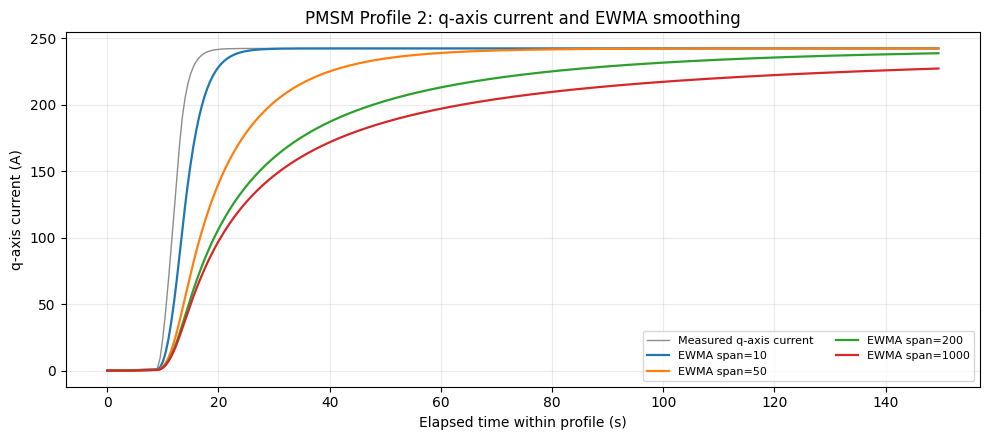

In [12]:
import matplotlib.pyplot as plt

pid = demo_ids[0]
mask = demo_df['profile_id'].eq(pid)
time_s = np.arange(int(mask.sum())) / FS_HZ

fig,ax=plt.subplots(figsize=(10,4.5))
ax.plot(time_s, X_temporal_demo.loc[mask,'i_q'].to_numpy(),
        label='Measured q-axis current', color='0.55', linewidth=1)
for s in DEMO_SPANS:
    ax.plot(time_s, X_temporal_demo.loc[mask,f'i_q_ewma_s{s}'].to_numpy(),
            label=f'EWMA span={s}', linewidth=1.6)
ax.set(xlabel='Elapsed time within profile (s)', ylabel='q-axis current (A)',
       title=f'PMSM Profile {pid}: q-axis current and EWMA smoothing')
ax.grid(alpha=.25)
ax.legend(ncol=2, fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/'ewma_real_profile.png', dpi=160)
plt.show()


## 2G · Export documentation evidence (not a cache)
Save a small **audit summary** and feature schema. These files are created from scratch every run and are not used as prerequisites. In Stage 3 the same feature functions will be called inside the model-training procedure with candidate smoothing spans; train-fitted standardization must be performed using *only the training profiles of each cross-validation fold*.


In [13]:
feature_audit = {
    'original_notebook_cells': '19–28',
    'source_paper': 'Kirchgässner et al. (2021), Table I and Sec. III-A',
    'development_demo_profiles': list(map(int,demo_ids)),
    'demo_rows': int(len(demo_df)),
    'source_sensor_count': 7,
    'derived_feature_count': 5,
    'illustrative_spans_samples': list(DEMO_SPANS),
    'sampling_hz': FS_HZ,
    'feature_count': int(X_temporal_demo.shape[1]),
    'feature_names': list(X_temporal_demo.columns),
    'ewma_convention': 'pandas ewm(span=s, adjust=True).mean()',
    'ewms_convention': 'pandas ewm(span=s, adjust=True).std(bias=True)',
    'model_training_performed': False,
    'final_test_evaluation_performed': False,
}
(OUTPUT_DIR/'stage2_feature_audit.json').write_text(json.dumps(feature_audit,indent=2))
pd.DataFrame({'feature_name':list(X_temporal_demo.columns)}).to_csv(
    OUTPUT_DIR/'stage2_feature_schema.csv',index=False
)
print('Generated: stage2_feature_audit.json, stage2_feature_schema.csv, ewma_real_profile.png')
print('No existing intermediate files were read. Final held-out profiles were not used.')


Generated: stage2_feature_audit.json, stage2_feature_schema.csv, ewma_real_profile.png
No existing intermediate files were read. Final held-out profiles were not used.


## Stage 2 conclusions and report notes

**What we demonstrated:** Seven original electrical/thermal/speed measurements were converted into twelve current-state predictors. For four illustrative spans, EWMA and EWMS added 96 causal, profile-specific history descriptors, producing a verified **600 × 108** demonstration matrix. Independent tests established agreement with the chosen weighted formulas, correct profile reset, correct feature dimensions, finite values, and no look-ahead on the tested sequences.

**What we have *not* established:** that four illustrative spans are optimal, that the 108 columns improve prediction, that the model generalizes to a new motor, or that the smoothing is sufficiently accurate for onboard thermal monitoring. These are empirical questions for cross-validation and later evaluation.

**Important experimental distinction:** Kirchgässner et al. optimise model-specific smoothing spans and train their regression models after standardizing using training data. Stage 3 must treat smoothing spans as model-selection parameters and fit any train-dependent scaler separately inside each cross-validation fold.

**Quick oral-check questions:**
1. What information does EWMA add that is missing from the instantaneous value?
2. How does EWMS differ from EWMA, and why could it help?
3. Why should smoothing restart at each `profile_id` boundary?
4. Why is `std(bias=True)` not identical to the printed right-hand side of Equation (4)?
5. Why should we not declare the 108-feature matrix better before testing a model?

**Next: Stage 3** — grouped three-fold cross-validation, train-only scaling, and fair regression-model comparison. Do not evaluate the locked final test profiles yet.


---
# Stage 3 · Grouped cross-validation, six-model smoke test, and OLS error diagnosis

**Reconstructs original 131-cell notebook Cells 29–45**. The stages above download raw data, check its integrity, reproduce the locked development/test split, and define feature-engineering functions.

This stage deliberately **does not** perform model optimisation or use the 14 held-out test profiles. It checks that fixed CV assignments and training pipelines function and studies a surprising OLS error. Small-sample results are **provisional** and should not be reported as final benchmark accuracy.

**Research trail:**

- Original Cells 29–34: stratified grouped three-fold CV from the 55 development profiles
- Cells 35–38: six regression pipelines on an 80-sample-per-profile demonstration set
- Cells 39–44: investigate an extreme OLS validation prediction
- Cell 45: interpret the results and prepare for Bayesian optimisation


## 3A · Why cross-validation must be grouped

Stage 1 reserved **14 complete profiles** for the final test. Here we further divide the remaining **55 complete development profiles** into three folds for model development. Each iteration trains on two folds and validates on the third; no recording session appears on both sides of the same iteration.

We stratify the *profiles*, not the individual 2 Hz observations, by tertiles of their **maximum measured magnet temperature**. The grouping helps balance lower- and higher-temperature sessions. It does not force equal observation counts because recording sessions differ in duration.

For a given model configuration, the later model-selection objective is

$$\mathrm{CV\,MSE}=\frac{1}{3}\sum_{k=1}^3\frac{1}{n_k}\sum_{i\in V_k}(y_i-\hat{y}_i)^2.$$

Each fold receives equal weight in this formula, **even when fold sizes differ**. These fold assignments will remain fixed for the forthcoming Bayesian optimisation. The final held-out set is not used for choosing models or hyperparameters.


In [14]:
from sklearn.model_selection import StratifiedKFold

# Rebuild fold assignments from Stage 1's *development* profiles only.
# The original notebook used random_state=42 on this sorted profile table.
profile_cv = (
    development_df.groupby('profile_id',sort=True)['pm']
    .agg(observations='size', pm_min='min', pm_max='max')
    .reset_index().sort_values('profile_id').reset_index(drop=True)
)
profile_cv['temperature_group'] = pd.qcut(
    profile_cv['pm_max'], q=3, labels=['Low','Medium','High']
)
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
profile_cv['cv_fold'] = -1
for fold_num, (_, val_idx) in enumerate(
    skf.split(profile_cv[['pm_max']], profile_cv['temperature_group']),start=1
):
    profile_cv.loc[val_idx,'cv_fold'] = fold_num

assert len(profile_cv)==55
assert profile_cv['cv_fold'].isin([1,2,3]).all()
assert set(profile_cv.profile_id).isdisjoint(test_ids)
assert profile_cv['profile_id'].is_unique

fold_train_val = {}
for fold_num in (1,2,3):
    val_ids = set(profile_cv.loc[profile_cv.cv_fold.eq(fold_num),'profile_id'].astype(int))
    train_ids = set(development_ids)-val_ids
    assert train_ids.isdisjoint(val_ids)
    assert val_ids.isdisjoint(test_ids)
    assert train_ids|val_ids==set(development_ids)
    fold_train_val[fold_num] = (sorted(train_ids),sorted(val_ids))

fold_summary = profile_cv.groupby('cv_fold',observed=True).agg(
    profiles=('profile_id','size'),observations=('observations','sum'),
    low_pm=('pm_min','min'),high_pm=('pm_max','max')
)
fold_summary['hours'] = fold_summary.observations / (FS_HZ*3600)
assert fold_summary.observations.sum() == len(development_df)
print('Temperature strata by fold:')
display(pd.crosstab(profile_cv.cv_fold,profile_cv.temperature_group))
print('Fold observation counts:')
display(fold_summary)
print('PASS: 55 development profiles assigned once each; final test remains excluded.')


Temperature strata by fold:


temperature_group,Low,Medium,High
cv_fold,,,
1,7,6,6
2,6,5,7
3,6,6,6


Fold observation counts:


,profiles,observations,low_pm,high_pm,hours
cv_fold,,,,,
1,19,401114,21.213623,109.333847,55.710278
2,18,362087,20.856956,105.948723,50.289861
3,18,291997,22.888792,99.396629,40.555139


PASS: 55 development profiles assigned once each; final test remains excluded.


### Interpret the fold summary

The original saved experiment gave **19/18/18 validation profiles**, with **401,114 / 362,087 / 291,997 observations** respectively. The difference in row counts is not an error: entire profiles must be kept together.

**Verification objective:** Can we reproduce the same exact split and confirm zero overlap? No prediction has been made yet.


## 3B · Build a small, physically consistent model-training demonstration

We select **80 evenly spaced observations from each of the 55 development profiles**, for a total of **4,400** rows. To avoid destroying the temporal meaning of EWMA/EWMS, we first generate features from **every original 2 Hz observation in each profile**, *then* select the demonstration positions.

**Important:** the 80 selected rows are not adjacent in time; their spacing differs with profile length. We retain `raw_position` and `elapsed_seconds` to diagnose where each selected observation really occurred. This sample is for **pipeline verification**, not the complete model benchmark.

The feature matrix has 12 original/derived predictors plus EWMA and EWMS at each of four *illustrative* spans `[10,50,200,1000]`, giving **108 features**. Final spans are chosen later by CV optimisation.


In [15]:
SMOKE_SPANS=(10,50,200,1000)
SAMPLES_PER_PROFILE=80

def make_pipeline_test_data(data, spans=SMOKE_SPANS, samples_per_profile=80):
    """Create a profile-balanced modelling sample without damaging 2 Hz feature history.

    The full sequential profile is transformed first; only then are a fixed
    number of time positions selected. Includes audit-only raw position/time.
    """
    parts=[]
    for pid, profile in data.groupby('profile_id',sort=False):
        X_raw=make_paper_inputs(profile)
        X_all=make_temporal_features(X_raw,profile['profile_id'],spans)
        count=min(samples_per_profile,len(profile))
        positions=np.linspace(0,len(profile)-1,count,dtype=int)
        sampled=X_all.iloc[positions].copy()
        sampled['pm_target']=profile['pm'].iloc[positions].to_numpy()
        sampled['profile_id']=int(pid)
        sampled['raw_position']=positions
        sampled['elapsed_seconds']=positions/FS_HZ
        parts.append(sampled)
    return pd.concat(parts,ignore_index=True)

smoke_df=make_pipeline_test_data(development_df,SMOKE_SPANS,SAMPLES_PER_PROFILE)
feature_cols=[c for c in smoke_df.columns if c not in
              ('pm_target','profile_id','raw_position','elapsed_seconds')]
assert len(smoke_df)==4_400 and smoke_df.profile_id.nunique()==55
assert len(feature_cols)==108
assert 'pm' not in feature_cols and 'profile_id' not in feature_cols
assert smoke_df[feature_cols].notna().all().all()
assert np.isfinite(smoke_df[feature_cols].to_numpy()).all()
assert (smoke_df.groupby('profile_id').raw_position.first()==0).all()
print('PASS:',len(smoke_df),'rows ×',len(feature_cols),'predictors across',
      smoke_df.profile_id.nunique(),'profiles')


PASS: 4400 rows × 108 predictors across 55 profiles


## 3C · Preliminary regression smoke test on **Fold 1 only**

Six model families are tested to confirm that the engineered features can be accepted by their training interfaces:

- **OLS:** ordinary least squares, linear regression
- **SVR:** nonlinear kernel regression, here RBF, `C=1`, `epsilon=0.1`
- **k-NN:** predicts using nearby examples in scaled feature space
- **Random Forest / Extra Trees:** ensembles of regression trees
- **MLP:** one-hidden-layer feed-forward neural network

A `Pipeline(StandardScaler(), model)` fits the scaling transformation **only on the current training fold**, then applies the same transformation to validation features. For tree ensembles this scaling is not necessary, but we retain it here to closely reconstruct the original experiment.

All six use *provisional parameters*, not tuned settings. Training and inference times will vary by hardware and library version. The MLP may report a convergence warning because the 150-iteration budget is intentionally small.


In [16]:
import time
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

train_profile_ids,val_profile_ids=fold_train_val[1]
train_sample=smoke_df.loc[smoke_df.profile_id.isin(train_profile_ids)].copy()
val_sample=smoke_df.loc[smoke_df.profile_id.isin(val_profile_ids)].copy()
assert set(train_sample.profile_id).isdisjoint(val_sample.profile_id)
assert len(train_sample)==36*80 and len(val_sample)==19*80

X_train=train_sample[feature_cols]
y_train=train_sample['pm_target']
X_val=val_sample[feature_cols]
y_val=val_sample['pm_target']

models={
    'OLS': LinearRegression(),
    'SVR': SVR(kernel='rbf',C=1.0,epsilon=0.1),
    'k-NN': KNeighborsRegressor(n_neighbors=10,weights='distance'),
    'Random Forest': RandomForestRegressor(n_estimators=20,max_depth=12,
                                          random_state=42,n_jobs=2),
    'Extra Trees': ExtraTreesRegressor(n_estimators=20,max_depth=12,
                                       random_state=42,n_jobs=2),
    'MLP': MLPRegressor(hidden_layer_sizes=(32,),max_iter=150,random_state=42)
}

results=[]
ols_pipeline=None
ols_predictions=None
for name, estimator in models.items():
    pipeline=Pipeline([('scaler',StandardScaler()),('model',estimator)])
    t0=time.perf_counter();pipeline.fit(X_train,y_train)
    fit_time=time.perf_counter()-t0
    t0=time.perf_counter();pred=pipeline.predict(X_val)
    predict_time=time.perf_counter()-t0
    errors=y_val.to_numpy()-pred
    results.append({
        'Model':name,
        'MSE (C^2)':mean_squared_error(y_val,pred),
        'RMSE (C)':np.sqrt(mean_squared_error(y_val,pred)),
        'MAE (C)':mean_absolute_error(y_val,pred),
        'R2':r2_score(y_val,pred),
        'Max absolute error (C)':np.abs(errors).max(),
        'Training time (s)':fit_time,
        'Inference time (s)':predict_time
    })
    if name=='OLS':
        ols_pipeline=pipeline
        ols_predictions=pred.copy()
    print('PASS:',name)

results_df=pd.DataFrame(results)
assert len(results_df)==6
assert np.isfinite(results_df.select_dtypes('number').to_numpy()).all()
print('Fold 1 only; exploratory pipeline smoke test (NOT final benchmark):')
display(results_df.round(4))


PASS: OLS
PASS: SVR
PASS: k-NN
PASS: Random Forest
PASS: Extra Trees
PASS: MLP
Fold 1 only; exploratory pipeline smoke test (NOT final benchmark):


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(


,Model,MSE (C^2),RMSE (C),MAE (C),R2,Max absolute error (C),Training time (s),Inference time (s)
0,OLS,88.6563,9.4157,6.3003,0.7667,213.7320,0.6611,0.0201
1,SVR,84.9066,9.2145,6.7282,0.7766,41.8656,2.9074,2.3415
2,k-NN,87.2593,9.3413,7.0180,0.7704,45.0894,0.0336,0.2084
3,Random Forest,94.2754,9.7096,7.5968,0.7520,42.8915,6.9103,0.0159
4,Extra Trees,57.5839,7.5884,5.7671,0.8485,35.3301,0.8560,0.0161
5,MLP,86.6788,9.3101,7.1344,0.7719,50.7575,4.7375,0.0105


### What do the metrics mean?

For measured temperature $y_i$ and prediction $\hat y_i$:

$$\mathrm{MSE}=\frac{1}{n}\sum_i (y_i-\hat y_i)^2, \qquad \mathrm{RMSE}=\sqrt{\mathrm{MSE}}$$
$$\mathrm{MAE}=\frac{1}{n}\sum_i|y_i-\hat y_i|, \qquad \mathrm{MaxAE}=\max_i |y_i-\hat y_i|.$$

- **MSE** penalises large errors quadratically; the units are °C².
- **RMSE** expresses that penalty back in °C.
- **MAE** gives an average error magnitude in °C, less dominated by a single extreme point.
- **Maximum absolute error** reveals whether an otherwise good model makes a dangerously bad prediction.
- **R²** describes improvement relative to predicting the validation mean; it can be negative.

The original saved Fold 1 pilot results were approximately: **OLS MSE 88.66**, **SVR 84.91**, **k-NN 87.26**, **Random Forest 94.28**, **Extra Trees 57.58**, and **MLP 86.68 °C²**. Small differences across software versions are not necessarily evidence of a methodological change. Crucially, this is one fold with untuned settings, so it is **not** a six-algorithm ranking for your final report.


## 3D · Investigate the surprising OLS prediction, without removing data

The original pilot produced an OLS prediction of approximately **239.77 °C** for one observation whose measured magnet temperature was approximately **26.04 °C** (recording **profile 65**). That is an absolute error of about **213.73 °C**.

Before changing the algorithm, investigate:

1. Which measured point had the greatest error?
2. Was it near the *real* beginning of a profile?
3. How much of total MSE was caused by just that one prediction?
4. Do the first observations of other profiles show the same behaviour?

**Subtle correction to the original notebook:** Original Cell 42 used `groupby(...).cumcount()` on *already subsampled* observations. That counts the position **within the 80-point sample**, not the true position within the original 2 Hz recording. In this rebuilt workflow, `raw_position` and `elapsed_seconds` preserve the true position/time from the original profile. In particular, `raw_position=0` is an actual profile-start measurement; the next selected sample may be many seconds later.


In [17]:
ols_diagnostics=val_sample[['profile_id','pm_target','raw_position',
                                'elapsed_seconds']].copy().reset_index(drop=True)
ols_diagnostics=ols_diagnostics.rename(columns={'pm_target':'actual_pm'})
ols_diagnostics['predicted_pm']=ols_predictions
ols_diagnostics['absolute_error']=(
    ols_diagnostics['actual_pm']-ols_diagnostics['predicted_pm']).abs()
ols_diagnostics['squared_error']=ols_diagnostics['absolute_error']**2

print('Largest OLS prediction errors:')
display(ols_diagnostics.nlargest(10,'absolute_error'))
worst=ols_diagnostics.loc[ols_diagnostics['squared_error'].idxmax()]
print('Worst prediction in profile',int(worst.profile_id),
      'at original sample',int(worst.raw_position),
      'elapsed time',round(float(worst.elapsed_seconds),2),'s')

first=ols_diagnostics.loc[ols_diagnostics.raw_position.eq(0)]
later=ols_diagnostics.loc[ols_diagnostics.raw_position.gt(0)]
assert len(first)==len(val_profile_ids)==19
print('Mean absolute error at actual first recorded samples:',
      first.absolute_error.mean())
print('Mean absolute error at later *selected* samples:',
      later.absolute_error.mean())

print('Profile 65 first five *selected* examples (not adjacent 0.5-s samples):')
display(ols_diagnostics.loc[ols_diagnostics.profile_id.eq(65)].head(5))


Largest OLS prediction errors:


,profile_id,actual_pm,raw_position,elapsed_seconds,predicted_pm,absolute_error,squared_error
1280,65,26.037928,0,0.0,239.769930,213.732002,45681.368552
1201,72,41.780465,193,96.5,79.972030,38.191565,1458.595641
641,15,31.670839,229,114.5,63.268627,31.597788,998.420185
642,15,41.445896,458,229.0,67.217468,25.771572,664.173933
474,27,75.651138,33122,16561.0,50.344875,25.306263,640.406969
473,27,82.210464,32674,16337.0,57.981359,24.229105,587.049537
1122,69,29.539304,388,194.0,53.191581,23.652277,559.430205
475,27,70.167656,33569,16784.5,46.599690,23.567966,555.449009
869,75,68.704834,11765,5882.5,46.433088,22.271746,496.030664
1121,69,27.300511,194,97.0,49.327319,22.026808,485.180262


Worst prediction in profile 65 at original sample 0 elapsed time 0.0 s
Mean absolute error at actual first recorded samples: 18.515433952689985
Mean absolute error at later *selected* samples: 6.145677494004604
Profile 65 first five *selected* examples (not adjacent 0.5-s samples):


,profile_id,actual_pm,raw_position,elapsed_seconds,predicted_pm,absolute_error,squared_error
1280,65,26.037928,0,0.0,239.769930,213.732002,45681.368552
1281,65,35.643693,507,253.5,49.005254,13.361560,178.531289
1282,65,40.722855,1015,507.5,47.186275,6.463419,41.775790
1283,65,53.522017,1522,761.0,62.603549,9.081532,82.474221
1284,65,61.693861,2030,1015.0,67.202789,5.508929,30.348296


## 3E · Quantify why a single extreme error matters

Squared-error metrics give disproportionate weight to rare large errors. To diagnose the sensitivity, compute the portion of total squared error attributable to the single worst prediction:

$$\mathrm{Influence\ percentage}=\frac{(y_j-\hat y_j)^2}{\sum_i(y_i-\hat y_i)^2}\times100\%$$

Compute the MSE again *without that one error* only as a **sensitivity diagnostic**. **Do not remove this valid observation from the official evaluation or subsequent development set** unless there is independent evidence that it is invalid.


In [18]:
err2=ols_diagnostics.squared_error
worst_idx=err2.idxmax()
influence_pct=100*err2.loc[worst_idx]/err2.sum()
full_mse=err2.mean()
illustrative_mse_wo_one=err2.drop(worst_idx).mean()

print('Largest-error share of squared-error sum:',round(influence_pct,2),'%')
print('Observed validation MSE, all 1520 points:',round(full_mse,4),'C^2')
print('Diagnostic-only MSE excluding largest error:',
      round(illustrative_mse_wo_one,4),'C^2')

if int(worst.profile_id)==65:
    print('Raw first five measured rows of profile 65:')
    display(development_df.loc[development_df.profile_id.eq(65)].head(5))

# Preservation and numerical check: original data remains untouched.
assert len(ols_diagnostics)==len(val_sample)==1520
assert np.isclose(full_mse,results_df.loc[results_df.Model.eq('OLS'),'MSE (C^2)'].iloc[0])
print('PASS: anomaly investigated with full data retained.')


Largest-error share of squared-error sum: 33.9 %
Observed validation MSE, all 1520 points: 88.6563 C^2
Diagnostic-only MSE excluding largest error: 58.6413 C^2
Raw first five measured rows of profile 65:


,u_q,coolant,stator_winding,u_d,stator_tooth,motor_speed,i_d,i_q,pm,stator_yoke,ambient,torque,profile_id
1042494,-0.060301,24.572270,25.328268,-0.044640,24.759084,3028.577653,-16.682717,-22.554878,26.037928,23.902619,25.156664,-5.036988,65
1042495,-0.098472,24.549411,25.332084,-0.087538,24.771273,3277.195135,-32.674103,-36.837572,26.171841,23.906777,25.158406,7.594919,65
1042496,-0.134579,24.529792,25.289755,-0.137843,24.780007,3526.252702,-51.436325,-50.341317,25.995341,23.909756,25.159215,19.732400,65
1042497,-0.163837,24.506268,25.284230,-0.188305,24.786265,3775.622429,-70.247635,-61.302441,25.900132,23.910191,25.157646,27.199507,65
1042498,-0.185884,24.494794,25.343128,-0.235406,24.790749,4025.182345,-87.820645,-69.577852,25.862153,23.911742,25.156261,30.220038,65


PASS: anomaly investigated with full data retained.


## 3F · Save reproducible evidence and explicitly stop before optimisation

These generated CSV/JSON files document what happened; the next execution of **Run all** regenerates them from the original raw dataset. They are *not* input dependencies for Stage 3.


In [19]:
profile_cv.to_csv(OUTPUT_DIR/'profile_cv_assignments.csv',index=False)
results_df.to_csv(OUTPUT_DIR/'stage3_fold1_smoke_models.csv',index=False)
ols_diagnostics.to_csv(OUTPUT_DIR/'stage3_ols_validation_diagnostics.csv',index=False)

stage3_audit={
 'source_notebook_cells':'29-45',
 'fixed_seed':42,
 'development_profiles':int(len(profile_cv)),
 'heldout_test_profiles_unused':len(test_ids),
 'folds':{str(k):{'train_profiles':len(v[0]),'validation_profiles':len(v[1])}
          for k,v in fold_train_val.items()},
 'smoke_spans':list(SMOKE_SPANS),
 'smoke_total_observations':int(len(smoke_df)),
 'smoke_sample_per_profile':SAMPLES_PER_PROFILE,
 'predictor_count':len(feature_cols),
 'fold1_validation_observations':len(val_sample),
 'results_are_final_benchmark':False,
 'worst_ols_profile':int(worst.profile_id),
 'worst_ols_raw_position':int(worst.raw_position),
 'worst_ols_absolute_error_C':float(worst.absolute_error),
 'worst_ols_error_contribution_percent':float(influence_pct),
 'final_test_evaluated':False,
 'bayesian_optimisation_performed':False,
}
(OUTPUT_DIR/'stage3_audit.json').write_text(json.dumps(stage3_audit,indent=2))
print('Generated: profile_cv_assignments.csv, stage3_fold1_smoke_models.csv,')
print('stage3_ols_validation_diagnostics.csv, stage3_audit.json')


Generated: profile_cv_assignments.csv, stage3_fold1_smoke_models.csv,
stage3_ols_validation_diagnostics.csv, stage3_audit.json


## Stage 3 conclusions and report notes

**What the original and rebuilt Stage 3 verify:**

- The profile-grouped, temperature-stratified three-fold scheme excludes the held-out final test set.
- A small *fixed-span, one-fold* pilot confirms that six regression implementations can consume the 108 engineered features.
- An extreme prediction from one linear model is diagnosed, not silently discarded.
- The pilot illustrates why it is insufficient to report only average MSE: inspect MAE, maximum deviation and individual failure modes.

**What this stage does NOT establish:** a best algorithm, optimised spans, representative full-development accuracy, or generalisation error on the 14 unseen final-test profiles. Those belong to later stages.

**Possible report paragraph (adapt to your actual rerun and cite source code/results):**

> To establish a leakage-resistant training and validation strategy, the 55 development sessions were partitioned into three temperature-stratified folds at the profile level. Preliminary implementations of six regressors were checked with 4,400 sampled observations whose temporal features were calculated from complete 2 Hz histories. A pronounced OLS prediction error in profile 65 motivated an error-influence study. The affected observation was retained because the evidence did not establish a sensor fault. These results motivated more systematic optimisation and robustness evaluation rather than premature model selection.

**Self-check before Stage 4:** (i) Why stratify by *profile* rather than row? (ii) Why standardize using the fold's training observations only? (iii) Why generate temporal features before sampling? (iv) Why is 57.58 °C² for Extra Trees *not* a final performance claim? (v) Why might MSE and MAE tell different stories for OLS?

**Next:** Stage 4 (original Cells 46–67), Bayesian optimisation of EWMA/EWMS spans and model hyperparameters using these fixed folds. No final-test data should influence that process.


---
# Stage 4 — Confirm the three-fold OLS objective and run the eight-candidate Bayesian pilot

Use 4,400 development observations for each candidate, with 108 features, the same three grouped validation folds, and the same row selections. This verifies the optimisation mechanism **without repeating the archived 28-trial OLS and five-model searches**. Those historical searches remain in the original notebook.


In [20]:
import json, time, warnings
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

N_OLS_PILOT_TRIALS = 8
OPTIMISATION_SEED = 42

STAGE4_DIR = OUTPUT_DIR / 'stage4'
STAGE4_DIR.mkdir(parents=True, exist_ok=True)

# The CV fold assignments were fixed during Stage 3.
fold_lookup = profile_cv.set_index('profile_id')['cv_fold']
assert len(fold_lookup) == 55 and set(fold_lookup.unique()) == {1, 2, 3}
assert set(fold_lookup.index).isdisjoint(set(test_ids))


def build_candidate_features(spans):
    """Build 108 causal features from raw development profiles.

    EWMAs/EWMSs use *all* preceding 2 Hz readings in each profile.
    Only after that do we retain 80 evenly spaced observations/profile.
    Different trial spans keep the identical row positions and CV folds.
    """
    spans = tuple(int(s) for s in spans)
    if len(spans) != 4 or not all(a < b for a,b in zip(spans,spans[1:])):
        raise ValueError('Exactly four distinct increasing spans required')
    feature_blocks, target_blocks, id_blocks = [], [], []
    for pid, profile in development_df.groupby('profile_id',sort=False):
        raw = make_paper_inputs(profile)
        temporal = make_temporal_features(raw,profile['profile_id'],spans)
        loc = np.linspace(0,len(profile)-1,SAMPLES_PER_PROFILE,dtype=int)
        feature_blocks.append(temporal.iloc[loc].to_numpy(dtype=np.float64))
        target_blocks.append(profile['pm'].iloc[loc].to_numpy(dtype=np.float64))
        id_blocks.append(np.full(len(loc),int(pid),dtype=int))
    X = np.vstack(feature_blocks)
    y = np.concatenate(target_blocks)
    ids = np.concatenate(id_blocks)
    assert X.shape == (4400,108) and y.shape == (4400,) and len(ids) == 4400
    assert np.isfinite(X).all() and np.isfinite(y).all()
    assert not np.isin(ids,test_ids).any()
    return X,y,ids


def evaluate_ols_cv(spans):
    """Calculate reproducible, 3-fold grouped validation errors for OLS."""
    X,y,ids = build_candidate_features(spans)
    folds = pd.Series(ids).map(fold_lookup).to_numpy(dtype=int)
    errors = []
    for fold in (1,2,3):
        tr,va = folds != fold,folds == fold
        assert set(ids[tr]).isdisjoint(set(ids[va]))
        pipeline = Pipeline([
            ('standardise_train_only',StandardScaler()),
            ('linear_regression',LinearRegression())
        ])
        pipeline.fit(X[tr],y[tr])
        prediction = pipeline.predict(X[va])
        errors.append(float(mean_squared_error(y[va],prediction)))
    return float(np.mean(errors)),errors

print('Stage 4 objective defined; final held-out profiles are untouched.')

Stage 4 objective defined; final held-out profiles are untouched.


## 4B · Numerically verify the unoptimised reference

The original pilot tested spans **(10, 50, 200, 1000)** using all three folds (not just the Fold 1 smoke test from Stage 3).

Original saved reference: Fold 1 = 88.6563; Fold 2 = 54.8137; Fold 3 = 50.4498; mean = **64.6399 °C²**. The assertion checks that our rebuild implements the same objective and partitions to the stated tolerance.

In [21]:
baseline_spans = (10,50,200,1000)
baseline_mse, baseline_folds = evaluate_ols_cv(baseline_spans)
for k,score in enumerate(baseline_folds,start=1):
    print(f'Fold {k} MSE = {score:.6f} °C²')
print(f'Baseline mean CV MSE = {baseline_mse:.6f} °C²')
np.testing.assert_allclose(baseline_mse,64.6399,rtol=0.001)
assert np.isclose(np.mean(baseline_folds),baseline_mse)
print('PASS: Baseline objective matches the original saved calculation')

Fold 1 MSE = 88.656261 °C²
Fold 2 MSE = 54.813706 °C²
Fold 3 MSE = 50.449841 °C²
Baseline mean CV MSE = 64.639936 °C²
PASS: Baseline objective matches the original saved calculation


### Eight-candidate Bayesian verification

`scikit-optimize` proposes four ordered spans, then the objective regenerates features and calculates the mean of three grouped-fold MSE values. This repeats only the original **pilot budget**. The best candidate may vary slightly with software versions.


In [22]:
# Install in fresh Colab once. Local/offline verification can execute
# all objective tests above without requiring this external dependency.
%pip -q install scikit-optimize
from skopt import gp_minimize, Optimizer
from skopt.space import Integer, Real, Categorical

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 1.7 MB/s eta 0:00:00


In [23]:
ols_search_space = [
    Integer(5,30,name='span_1'),
    Integer(31,150,name='span_2'),
    Integer(151,700,name='span_3'),
    Integer(701,3000,name='span_4')
]
ols_pilot_records=[]

def ols_pilot_objective(candidate):
    spans = tuple(map(int,candidate))
    start = time.perf_counter()
    avg,fold_scores = evaluate_ols_cv(spans)
    ols_pilot_records.append({
        'trial':len(ols_pilot_records)+1,
        **{f's{i}':v for i,v in enumerate(spans,start=1)},
        **{f'fold{i}_mse':float(v) for i,v in enumerate(fold_scores,start=1)},
        'mean_cv_mse':avg,
        'runtime_s':time.perf_counter()-start
    })
    print(f'OLS pilot {len(ols_pilot_records):2}/{N_OLS_PILOT_TRIALS}: '
          f'spans={spans}, CV MSE={avg:.4f} °C²',flush=True)
    return avg

ols_pilot_result = gp_minimize(
    ols_pilot_objective,
    dimensions=ols_search_space,
    n_calls=N_OLS_PILOT_TRIALS,
    n_initial_points=4,
    acq_func='EI',
    random_state=OPTIMISATION_SEED
)
ols_pilot_df=pd.DataFrame(ols_pilot_records)
ols_pilot_df.to_csv(STAGE4_DIR/'ols_eight_trial_pilot.csv',index=False)
assert len(ols_pilot_df)==8
assert np.isfinite(ols_pilot_df[['fold1_mse','fold2_mse','fold3_mse','mean_cv_mse']].to_numpy()).all()
np.testing.assert_allclose(ols_pilot_df[['fold1_mse','fold2_mse','fold3_mse']].mean(axis=1),
                           ols_pilot_df['mean_cv_mse'])
print('Best eight-trial OLS spans:',list(map(int,ols_pilot_result.x)))
print('Best eight-trial CV MSE:',float(ols_pilot_result.fun))
display(ols_pilot_df.sort_values('mean_cv_mse').head(8).round(4))

OLS pilot  1/8: spans=(25, 53, 579, 2073), CV MSE=48.3574 °C²
OLS pilot  2/8: spans=(16, 43, 403, 1468), CV MSE=53.7103 °C²
OLS pilot  3/8: spans=(9, 108, 182, 2361), CV MSE=48.6122 °C²
OLS pilot  4/8: spans=(28, 31, 696, 2121), CV MSE=47.8367 °C²
OLS pilot  5/8: spans=(30, 31, 700, 2347), CV MSE=47.1058 °C²
OLS pilot  6/8: spans=(30, 31, 700, 3000), CV MSE=45.9508 °C²
OLS pilot  7/8: spans=(30, 150, 652, 3000), CV MSE=45.6467 °C²
OLS pilot  8/8: spans=(5, 150, 700, 3000), CV MSE=45.7540 °C²
Best eight-trial OLS spans: [30, 150, 652, 3000]
Best eight-trial CV MSE: 45.64670386344714


,trial,s1,s2,s3,s4,fold1_mse,fold2_mse,fold3_mse,mean_cv_mse,runtime_s
6,7,30,150,652,3000,65.8372,37.5159,33.5870,45.6467,8.7936
7,8,5,150,700,3000,65.9788,36.9979,34.2855,45.7540,7.4857
5,6,30,31,700,3000,66.1333,37.6906,34.0287,45.9508,8.3611
4,5,30,31,700,2347,67.9360,38.8915,34.4900,47.1058,7.3669
3,4,28,31,696,2121,68.9513,39.5925,34.9663,47.8367,8.5188
0,1,25,53,579,2073,69.7459,40.1931,35.1333,48.3574,19.9066
2,3,9,108,182,2361,70.0873,40.4242,35.3250,48.6122,9.5214
1,2,16,43,403,1468,76.3572,44.9916,39.7820,53.7103,18.6554


## 4D · Inspect objective progress and search-boundary effects

The expected reduction in prediction error is **empirical**, not a guarantee of generalisation. Examine whether the best spans land against their search boundaries; if they do, that motivates investigating a wider parameter domain. The best-so-far curve is non-increasing, but the individual candidate errors may go up or down.

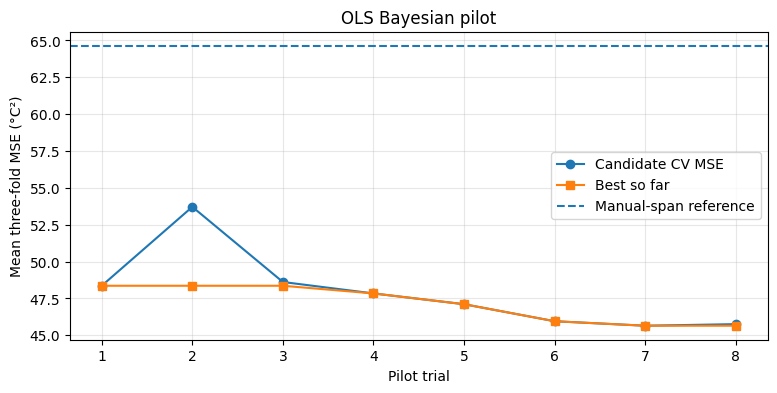

Relative MSE reduction from baseline: 29.38%


In [24]:
import matplotlib.pyplot as plt
history=ols_pilot_df.copy()
history['best_so_far']=history.mean_cv_mse.cummin()
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(history.trial,history.mean_cv_mse,'o-',label='Candidate CV MSE')
ax.plot(history.trial,history.best_so_far,'s-',label='Best so far')
ax.axhline(baseline_mse,ls='--',label='Manual-span reference')
ax.set(xlabel='Pilot trial',ylabel='Mean three-fold MSE (°C²)',title='OLS Bayesian pilot')
ax.grid(alpha=0.3);ax.legend();plt.show()
print(f'Relative MSE reduction from baseline: '
      f'{100*(baseline_mse-ols_pilot_df.mean_cv_mse.min())/baseline_mse:.2f}%')

### Verify that the expanded parameterisation can represent ordered spans

The archive subsequently searched a much larger range. Here we check the encoding and decoding only; we do **not** rerun its extra evaluations.


In [25]:
expanded_space = [
    Integer(5,100,name='s1'),
    Integer(1,400,name='gap_2'),
    Integer(1,1500,name='gap_3'),
    Integer(1,6000,name='gap_4')
]

def decode_spans(parameters):
    a,d2,d3,d4=map(int,parameters)
    return [a,a+d2,a+d2+d3,a+d2+d3+d4]

def encode_spans(spans):
    a,b,c,d=map(int,spans)
    if not (a<b<c<d):
        raise ValueError('Expected strictly increasing spans')
    return [a,b-a,c-b,d-c]

for example in [(10,50,200,1000),(30,150,652,3000),(89,265,622,3829)]:
    assert decode_spans(encode_spans(example)) == list(example)
for _,row in ols_pilot_df.iterrows():
    params=encode_spans([row[f's{i}'] for i in range(1,5)])
    assert all(dim.low <= val <= dim.high for dim,val in zip(expanded_space,params))
print('PASS: Ordered-span encoding is invertible and pilot trials fit enlarged space')

print('PASS: Expanded ordered-span parameterisation verified; no extended search performed.')


PASS: Ordered-span encoding is invertible and pilot trials fit enlarged space
PASS: Expanded ordered-span parameterisation verified; no extended search performed.


### Define alternative model implementations (not a new five-model search)

The regression factories are used in later checks. The historical 8- and 12-evaluation searches are documented in the original notebook, not replayed here.


In [26]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor,ExtraTreesRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.exceptions import ConvergenceWarning

MODEL_SPACES = {
    'SVR': [Real(1e-3,10,prior='log-uniform',name='C'),
            Real(1e-2,0.3,prior='log-uniform',name='epsilon')],
    'k-NN': [Integer(1,512,name='n_neighbors'),
              Categorical(['uniform','distance'],name='weights')],
    'Random Forest': [Integer(20,100,name='n_estimators'),
                      Integer(5,30,name='max_depth'),
                      Integer(2,20,name='min_samples_split'),
                      Integer(1,10,name='min_samples_leaf'),
                      Categorical(['yes','no'],name='bootstrap')],
    'Extra Trees': [Integer(20,100,name='n_estimators'),
                    Integer(5,30,name='max_depth'),
                    Integer(2,20,name='min_samples_split'),
                    Integer(1,10,name='min_samples_leaf'),
                    Categorical(['yes','no'],name='bootstrap')],
    'MLP': [Integer(1,3,name='n_layers'),
            Integer(4,32,name='n_units'),
            Real(1e-7,1e-2,prior='log-uniform',name='alpha'),
            Real(1e-4,1e-2,prior='log-uniform',name='learning_rate_init')]
}

def make_regressor(model_name,hp):
    if model_name=='SVR':
        return SVR(kernel='rbf',C=float(hp['C']),epsilon=float(hp['epsilon']),gamma='scale')
    if model_name=='k-NN':
        return KNeighborsRegressor(n_neighbors=int(hp['n_neighbors']),
                                   weights=hp['weights'],n_jobs=2)
    if model_name in ('Random Forest','Extra Trees'):
        cls=RandomForestRegressor if model_name=='Random Forest' else ExtraTreesRegressor
        return cls(n_estimators=int(hp['n_estimators']),
                   max_depth=int(hp['max_depth']),
                   min_samples_split=int(hp['min_samples_split']),
                   min_samples_leaf=int(hp['min_samples_leaf']),
                   bootstrap=(hp['bootstrap']=='yes'),max_features='sqrt',
                   random_state=42,n_jobs=2)
    if model_name=='MLP':
        return MLPRegressor(hidden_layer_sizes=(int(hp['n_units']),)*int(hp['n_layers']),
                            alpha=float(hp['alpha']),activation='relu',solver='adam',
                            learning_rate_init=float(hp['learning_rate_init']),
                            batch_size=64,max_iter=200,random_state=42,
                            early_stopping=False)
    raise ValueError(f'Unknown model: {model_name}')


def evaluate_model_cv(model_name,candidate):
    spans=decode_spans(candidate[:4])
    hp={dim.name:(val.item() if isinstance(val,np.generic) else val)
        for dim,val in zip(MODEL_SPACES[model_name],candidate[4:])}
    X,y,ids=build_candidate_features(spans)
    folds=pd.Series(ids).map(fold_lookup).to_numpy(dtype=int)
    errors=[];convergence_warnings=0
    for k in (1,2,3):
        tr,va=folds!=k,folds==k
        assert set(ids[tr]).isdisjoint(set(ids[va]))
        pipe=TransformedTargetRegressor(
            regressor=Pipeline([('scaler',StandardScaler()),
                                ('model',make_regressor(model_name,hp))]),
            transformer=StandardScaler()
        )
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always',ConvergenceWarning)
            pipe.fit(X[tr],y[tr])
        convergence_warnings+=sum(
            issubclass(w.category,ConvergenceWarning) for w in caught)
        y_hat=pipe.predict(X[va])
        assert np.isfinite(y_hat).all()
        errors.append(float(mean_squared_error(y[va],y_hat)))
    return {'spans':spans,'hyperparameters':hp,
            'fold_scores':errors,'mean_cv_mse':float(np.mean(errors)),
            'convergence_warnings':convergence_warnings}

print('PASS: Five model-specific search spaces and CV objectives defined')

PASS: Five model-specific search spaces and CV objectives defined


**Stage 4 checkpoint:** The three-fold objective and eight-trial OLS pilot can be regenerated. Optimisation quality beyond that pilot remains supported by the **original saved research outputs**, not by the present Run All.


---
# Stage 5 — SVR sample-size verification

Build causal features from complete 2-Hz histories, choose nested development samples, and measure two manageable training budgets (80 and 160 rows per profile) across all three folds. The original 320/640 budgets and repeated timing experiments are **historical results**, not rerun in this verification notebook.


In [27]:
import os, json, heapq, time, platform
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

STAGE5_DIR = OUTPUT_DIR / 'stage5'
STAGE5_DIR.mkdir(parents=True, exist_ok=True)

STAGE5_SAMPLE_SIZES = (80, 160, 320, 640)  # Nested sample construction and audit
STAGE5_MAX_SAMPLES = max(STAGE5_SAMPLE_SIZES)
STAGE5_EVALUATED_SIZES = (80, 160)  # Fixed verification scope
STAGE5_REPEATS = 1  # One fit per grouped fold (6 fits in total)

# Original Stage 4 pilot's saved winner (fixed here, not silently loaded from Drive).
STAGE5_SPANS = (47, 301, 1799, 6668)
STAGE5_SVR_HP = {
    'C': 1.573090181238779,
    'epsilon': 0.18308574912799475,
    'gamma': 'scale',
    'kernel': 'rbf'
}
STAGE5_CONFIG_SOURCE = 'original Stage 4 eight-evaluation SVR pilot (fixed recorded winner)'

assert len(STAGE5_SPANS) == 4 and list(STAGE5_SPANS) == sorted(STAGE5_SPANS)
assert set(development_df.profile_id).isdisjoint(test_ids)
assert len(development_df) == 1_055_198 and development_df.profile_id.nunique() == 55
assert STAGE5_REPEATS in (1,3)

print('Frozen SVR spans:', STAGE5_SPANS)
print('Frozen SVR hyperparameters:', STAGE5_SVR_HP)
print('Stage 5 model-fit budgets:', STAGE5_EVALUATED_SIZES)
print('Stage 5 repetitions per size/fold:',STAGE5_REPEATS)
print('No final-test profiles used.')

Frozen SVR spans: (47, 301, 1799, 6668)
Frozen SVR hyperparameters: {'C': 1.573090181238779, 'epsilon': 0.18308574912799475, 'gamma': 'scale', 'kernel': 'rbf'}
Stage 5 model-fit budgets: (80, 160)
Stage 5 repetitions per size/fold: 1
No final-test profiles used.


## 5B · Why nested samples are a stronger experimental design

We want a sequence of training subsets $A_{80}\subset A_{160}\subset A_{320}\subset A_{640}$ **within each profile**. The original implementation begins with the first and last observation, then repeatedly bisects the *largest remaining interval*. Each refinement adds observations; it does not replace old observations.

At 2 Hz, an EWMA span of 6668 retains a long history. We therefore calculate temporal features from **each complete original profile** before selecting any rows. Selecting first and smoothing second would incorrectly treat widely separated observations as adjacent in time.

For any training fold with $p$ training profiles, the number of training rows is $p\times n$, where $n$ is 80, 160, 320 or 640. All validation folds use **the same 640 observations per validation profile at every training size**.

In [28]:
def nested_sample_order(profile_length: int, max_samples: int) -> list[int]:
    """Return nested sample positions in selection order (not time order).

    Repeatedly bisects the largest interval, preserving first and last
    positions. For every n in (80,160,320,640), the first n selections
    are a strict subset of the first 2n selections when those exist.
    """
    if not (2 <= max_samples <= profile_length):
        raise ValueError('Require 2 <= max_samples <= profile_length')
    selected = [0, profile_length - 1]
    intervals = [(-(profile_length - 1), 0, profile_length - 1)]
    while len(selected) < max_samples:
        _, left, right = heapq.heappop(intervals)
        midpoint = (left + right) // 2
        if midpoint in (left, right):
            continue
        selected.append(midpoint)
        for a,b in ((left,midpoint),(midpoint,right)):
            if b-a > 1:
                heapq.heappush(intervals, (-(b-a),a,b))
    assert len(selected) == len(set(selected)) == max_samples
    return selected

# Independent low-cost verification before transforming the 1.05M-row dataset.
example_order = nested_sample_order(2500, 640)
for n in STAGE5_SAMPLE_SIZES:
    assert len(set(example_order[:n])) == n
for low,high in zip(STAGE5_SAMPLE_SIZES[:-1],STAGE5_SAMPLE_SIZES[1:]):
    assert set(example_order[:low]).issubset(set(example_order[:high]))
assert example_order[:2] == [0, 2499]
print('PASS: Nesting and boundary tests on an independent 2,500-row example')

PASS: Nesting and boundary tests on an independent 2,500-row example


## 5C · Generate all 108 features from complete profile histories

For each of the 55 development profiles:

1. Convert the original sensors to twelve instantaneous engineering predictors.
2. Generate EWMA/EWMS using the **frozen** four spans, with profile history never crossing recording boundaries.
3. Select a maximum of 640 observations, preserving a `nest_rank` that indicates at which training budget each observation becomes available.
4. Reassemble one 35,200-row sampled development table, with 108 predictor columns and separate `pm_target`/`profile_id`/`nest_rank` metadata.

The large sampled matrix is *regenerated* and does not need to be stored in GitHub or Google Drive to run the experiment.

**Implementation improvement:** Stage 5 uses 12-column vectorised Pandas EWM calculations and checks them against the original Stage 2 definition. This avoids 96 separate per-column calls while preserving identical causal features.


In [29]:
def vectorised_temporal_sample(X_original, positions, spans):
    """Sample causal EWM features with 12-column vectorised Pandas filters.

    Returns exactly the same columns/values as make_temporal_features,
    but avoids looping separately over 96 individual feature series.
    Every EWM is computed over the full original profile *before* sampling.
    """
    sampled_columns = {col: X_original[col].iloc[positions].to_numpy()
                       for col in X_original.columns}
    for s in spans:
        ewm = X_original.ewm(span=int(s), adjust=True)
        historical_mean = ewm.mean().iloc[positions]
        historical_std = ewm.std(bias=True).iloc[positions]
        for col in X_original.columns:
            sampled_columns[f'{col}_ewma_s{s}'] = historical_mean[col].to_numpy()
            sampled_columns[f'{col}_ewms_s{s}'] = historical_std[col].to_numpy()
    return pd.DataFrame(sampled_columns,index=X_original.index[positions])

# Confirm vectorised and original implementations agree on real data.
_check_profile = next(iter(development_df.groupby('profile_id',sort=False)))[1].iloc[:450]
_check_raw = make_paper_inputs(_check_profile)
_check_positions = np.array([0,1,2,6,42,123,449])
_check_orig = make_temporal_features(_check_raw, _check_profile['profile_id'], STAGE5_SPANS)
_check_fast = vectorised_temporal_sample(_check_raw, _check_positions, STAGE5_SPANS)
np.testing.assert_allclose(
    _check_fast[_check_orig.columns].to_numpy(),
    _check_orig.iloc[_check_positions].to_numpy(),
    rtol=1e-9, atol=1e-9
)
print('PASS: Vectorised filters agree with Stage 2 reference on original sensor values')

started_features = time.perf_counter()
nested_parts = []

for profile_count, (profile_id, profile) in enumerate(
    development_df.groupby('profile_id', sort=False), start=1
):
    if not profile.index.is_monotonic_increasing:
        raise ValueError('Profile rows must be ordered chronologically')
    selection_order = nested_sample_order(len(profile), STAGE5_MAX_SAMPLES)
    positions = np.sort(np.asarray(selection_order, dtype=int))
    rank = {pos: i for i, pos in enumerate(selection_order)}

    X_original = make_paper_inputs(profile)
    sample = vectorised_temporal_sample(X_original, positions, STAGE5_SPANS)
    sample['pm_target'] = profile['pm'].iloc[positions].to_numpy(dtype=float)
    sample['profile_id'] = int(profile_id)
    sample['nest_rank'] = [rank[int(pos)] for pos in positions]
    nested_parts.append(sample)
    if profile_count % 10 == 0 or profile_count == 55:
        print(f'Processed {profile_count}/55 profiles',flush=True)

stage5_data = pd.concat(nested_parts, ignore_index=True)
stage5_feature_time_s = time.perf_counter() - started_features
stage5_feature_cols = [c for c in stage5_data.columns
    if c not in ('pm_target','profile_id','nest_rank')]
assert stage5_data.shape[0] == 55 * STAGE5_MAX_SAMPLES == 35_200
assert len(stage5_feature_cols) == 108
assert stage5_data.profile_id.nunique() == 55
assert stage5_data.nest_rank.between(0,STAGE5_MAX_SAMPLES-1).all()
assert np.isfinite(stage5_data[stage5_feature_cols+['pm_target']].to_numpy()).all()
assert set(stage5_data.profile_id).isdisjoint(test_ids)
for n in STAGE5_SAMPLE_SIZES:
    sample_counts = stage5_data.loc[stage5_data.nest_rank < n].groupby('profile_id').size()
    assert len(sample_counts) == 55 and sample_counts.eq(n).all()
    print(f'PASS: {n} per profile -> {55*n:,} selected development rows')
print(f'Feature preparation took {stage5_feature_time_s:.2f} s on this runtime')


PASS: Vectorised filters agree with Stage 2 reference on original sensor values
Processed 10/55 profiles
Processed 20/55 profiles
Processed 30/55 profiles
Processed 40/55 profiles
Processed 50/55 profiles
Processed 55/55 profiles
PASS: 80 per profile -> 4,400 selected development rows
PASS: 160 per profile -> 8,800 selected development rows
PASS: 320 per profile -> 17,600 selected development rows
PASS: 640 per profile -> 35,200 selected development rows
Feature preparation took 7.23 s on this runtime


## 5D · Controlled grouped three-fold SVR scalability experiment

For each training budget and fold:

- Train on profiles **outside** the fold, using `nest_rank < n`.
- Validate on profiles **inside** the fold, using **all 640 sampled validation observations per profile** regardless of training size.
- Fit the feature and target `StandardScaler`s using the **training fold only**.
- Measure wall-clock training time, prediction time, validation MSE in °C², and number of fitted support vectors.

For each budget we evaluate folds 1–3. If `STAGE5_REPEATS=3`, we repeat each fixed size/fold configuration three times to obtain more stable timing estimates. These repetitions **are not independent test splits**.

| Validation fold | Training profiles | Validation profiles | Constant validation rows |
|---|---:|---:|---:|
| 1 | 36 | 19 | 12,160 |
| 2 | 37 | 18 | 11,520 |
| 3 | 37 | 18 | 11,520 |

`Stage 5` uses only saved pilot settings; it does not run a new Bayesian optimisation or compare against the final 14 untouched test profiles.

**Verification scope:** This Run-All notebook evaluates **80 and 160 training observations per profile only**, with **one fit per grouped fold**. It constructs the larger 320/640 nested samples for feature verification and validation consistency but **does not fit SVR at those training sizes**. The original four-budget, three-repetition experiment is retained as historical evidence in Section 5E, not reproduced here. Therefore, any 'best' training budget found below is best **only among 80 and 160**, not best across the original four budgets. No additional execution-mode switch is needed.


In [30]:
stage5_fold_lookup = profile_cv.set_index('profile_id')['cv_fold'].astype(int)
stage5_data['cv_fold'] = stage5_data.profile_id.map(stage5_fold_lookup)
assert stage5_data.cv_fold.isin([1,2,3]).all()
assert set(stage5_data.profile_id).isdisjoint(test_ids)

stage5_records=[]
for n in STAGE5_EVALUATED_SIZES:
    for fold in (1,2,3):
        is_train = stage5_data.cv_fold.ne(fold) & stage5_data.nest_rank.lt(n)
        is_validation = stage5_data.cv_fold.eq(fold)
        tr = stage5_data.loc[is_train]
        va = stage5_data.loc[is_validation]
        assert set(tr.profile_id).isdisjoint(set(va.profile_id))
        assert len(tr) == tr.profile_id.nunique()*n
        # Crucial: Validation observations remain fixed as training size varies.
        assert len(va) == va.profile_id.nunique()*STAGE5_MAX_SAMPLES

        X_tr = tr[stage5_feature_cols].to_numpy(dtype=np.float64)
        y_tr = tr.pm_target.to_numpy(dtype=np.float64)
        X_va = va[stage5_feature_cols].to_numpy(dtype=np.float64)
        y_va = va.pm_target.to_numpy(dtype=np.float64)

        for repeat in range(1,STAGE5_REPEATS+1):
            estimator=TransformedTargetRegressor(
                regressor=Pipeline([
                    ('scaler',StandardScaler()),
                    ('svr',SVR(**STAGE5_SVR_HP))
                ]),
                transformer=StandardScaler()
            )
            start=time.perf_counter()
            estimator.fit(X_tr,y_tr)
            train_s=time.perf_counter()-start
            start=time.perf_counter()
            prediction=estimator.predict(X_va)
            inference_s=time.perf_counter()-start
            mse=float(mean_squared_error(y_va,prediction))
            fitted_svr=estimator.regressor_.named_steps['svr']
            stage5_records.append({
                'Samples_per_Profile':n,'Fold':fold,'Repeat':repeat,
                'Training_Rows':len(tr),'Validation_Rows':len(va),
                'Training_Time_s':train_s,'Inference_Time_s':inference_s,
                'MSE':mse,'Support_Vectors':len(fitted_svr.support_),
                'Input_Matrix_MB':(X_tr.nbytes+X_va.nbytes)/1e6
            })
            print(f'n={n:>3}, fold={fold}, repeat={repeat}: '
                  f'MSE={mse:.4f} °C²; fit={train_s:.2f}s',flush=True)

stage5_results=pd.DataFrame(stage5_records)
assert len(stage5_results)==len(STAGE5_EVALUATED_SIZES)*3*STAGE5_REPEATS
assert np.isfinite(stage5_results[['MSE','Training_Time_s','Inference_Time_s']].to_numpy()).all()
stage5_results.to_csv(STAGE5_DIR/'svr_nested_scalability.csv',index=False)
print(f'PASS: {len(stage5_results)} full training/validation fits completed')

n= 80, fold=1, repeat=1: MSE=41.1305 °C²; fit=1.05s
n= 80, fold=2, repeat=1: MSE=31.8229 °C²; fit=0.71s
n= 80, fold=3, repeat=1: MSE=36.1783 °C²; fit=0.63s
n=160, fold=1, repeat=1: MSE=38.2014 °C²; fit=2.94s
n=160, fold=2, repeat=1: MSE=31.3518 °C²; fit=1.44s
n=160, fold=3, repeat=1: MSE=39.7700 °C²; fit=2.38s
PASS: 6 full training/validation fits completed


## 5E · Summarise accuracy and runtime without conflating repetitions and CV folds

Take the **median runtime across repetitions within each fold**. Then compute each training-size configuration's **arithmetic mean of the three fold MSEs**. Between-fold SD describes variation across different validation profiles; repeating the same deterministic fit does not constitute independent CV evidence.

**Original saved benchmark (Cell 78):** at sample budgets 80, 160, 320, 640, the mean three-fold CV MSE values were 36.3772, 36.4411, 36.0818, and 38.3040 °C². The total three-fold fit times in the displayed saved output were 0.7437, 1.9688, 5.3700, and 13.9876 seconds. Treat timings as hardware- and environment-specific; do not assert exact timing equality across runtimes.

Note: the original notebook's narrative Cell 77 reported slightly different fit times than its saved output Cell 78; our audit uses measured outputs from **this** run and keeps the recorded saved outputs as the historical benchmark.

In [31]:
stage5_by_fold=(stage5_results.groupby(['Samples_per_Profile','Fold'],as_index=False)
    .agg(MSE=('MSE','mean'),
         Training_Rows=('Training_Rows','first'),
         Validation_Rows=('Validation_Rows','first'),
         Training_Time_s=('Training_Time_s','median'),
         Inference_Time_s=('Inference_Time_s','median'),
         Support_Vectors=('Support_Vectors','median'),
         Input_Matrix_MB=('Input_Matrix_MB','first')))
stage5_summary=(stage5_by_fold.groupby('Samples_per_Profile',as_index=False)
    .agg(Mean_CV_MSE=('MSE','mean'),
         Between_Fold_MSE_SD=('MSE','std'),
         Total_3Fold_Training_s=('Training_Time_s','sum'),
         Total_3Fold_Inference_s=('Inference_Time_s','sum'),
         Mean_Support_Vectors=('Support_Vectors','mean')))
assert len(stage5_summary)==len(STAGE5_EVALUATED_SIZES)
assert stage5_by_fold.groupby('Samples_per_Profile').size().eq(3).all()
stage5_by_fold.to_csv(STAGE5_DIR/'svr_scalability_by_fold.csv',index=False)
stage5_summary.to_csv(STAGE5_DIR/'svr_scalability_summary.csv',index=False)
print('Per-fold data:')
display(stage5_by_fold.round(4))
print('Three-fold summary:')
display(stage5_summary.round(4))

Per-fold data:


,Samples_per_Profile,Fold,MSE,Training_Rows,Validation_Rows,Training_Time_s,Inference_Time_s,Support_Vectors,Input_Matrix_MB
0,80,1,41.1305,2880,12160,1.0533,2.4380,689.0,12.9946
1,80,2,31.8229,2960,11520,0.7084,4.3113,687.0,12.5107
2,80,3,36.1783,2960,11520,0.6254,3.4844,627.0,12.5107
3,160,1,38.2014,5760,12160,2.9388,3.9724,997.0,15.4829
4,160,2,31.3518,5920,11520,1.4399,3.6785,950.0,15.0682
5,160,3,39.7700,5920,11520,2.3769,4.3056,911.0,15.0682


Three-fold summary:


,Samples_per_Profile,Mean_CV_MSE,Between_Fold_MSE_SD,Total_3Fold_Training_s,Total_3Fold_Inference_s,Mean_Support_Vectors
0,80,36.3772,4.6570,2.3871,10.2337,667.6667
1,160,36.4411,4.4767,6.7556,11.9565,952.6667


## 5F · Make the accuracy–computation trade-off visible

The two plots below are generated from the **current Run-All verification's 80- and 160-observations-per-profile results only**. A lower MSE is better, whereas rising training time indicates greater computational cost. A two-point verification plot cannot establish an optimal sampling budget or predict full-data SVR feasibility for all 1.05 million development observations.

**Historical comparison, not recomputed here:** In the original four-budget experiment, increasing from 320 to 640 observations per profile raised foldwise validation MSE by **+3.1633**, **+0.3136** and **+3.1895 °C²** for folds 1–3. The recorded four-budget mean CV MSE was lowest at **320 observations/profile (36.0818 °C²)**; that historical result should not be confused with the best of the two budgets evaluated in this verification run.

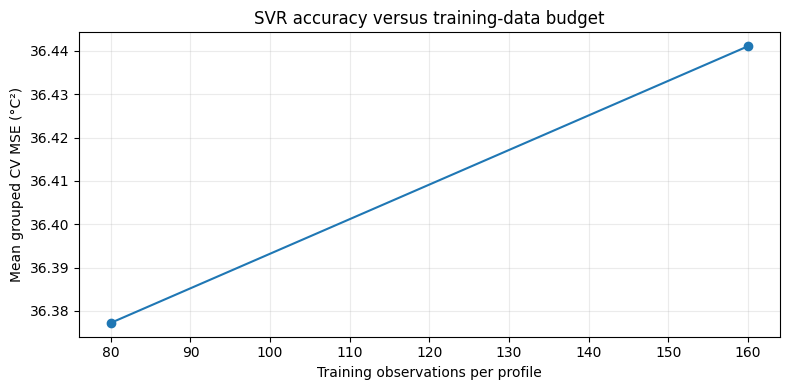

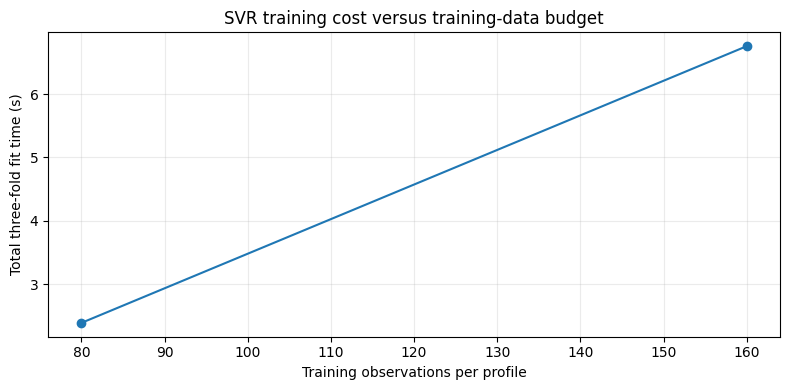

Verification scope: 80 and 160 training observations/profile only.
Historical 320-versus-640 comparison: not rerun; see Sections 5E–5F.
Lowest mean CV MSE among verification budgets (NOT the historical four-budget optimum): 80


In [32]:
import matplotlib.pyplot as plt
fig, ax=plt.subplots(figsize=(8,4))
ax.plot(stage5_summary.Samples_per_Profile,stage5_summary.Mean_CV_MSE,'o-')
ax.set(xlabel='Training observations per profile',ylabel='Mean grouped CV MSE (°C²)',
       title='SVR accuracy versus training-data budget')
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(STAGE5_DIR/'svr_accuracy_vs_budget.png',dpi=180)
plt.show()

fig, ax=plt.subplots(figsize=(8,4))
ax.plot(stage5_summary.Samples_per_Profile,stage5_summary.Total_3Fold_Training_s,'o-')
ax.set(xlabel='Training observations per profile',ylabel='Total three-fold fit time (s)',
       title='SVR training cost versus training-data budget')
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(STAGE5_DIR/'svr_fit_time_vs_budget.png',dpi=180)
plt.show()

# This verification run evaluates only the two explicitly declared training budgets.
assert set(stage5_summary['Samples_per_Profile']) == {80, 160}
print('Verification scope: 80 and 160 training observations/profile only.')
print('Historical 320-versus-640 comparison: not rerun; see Sections 5E–5F.')
print('Lowest mean CV MSE among verification budgets (NOT the historical four-budget optimum):',
      int(stage5_summary.loc[stage5_summary.Mean_CV_MSE.idxmin(),'Samples_per_Profile']))

## 5G · Export a reproducibility and engineering audit

The audit records the frozen settings, exact raw dataset checksum, software versions, training budgets and summary. The CSV and figures are **generated outputs**, never prerequisites for Run All.

In [33]:
stage5_audit={
  'original_notebook_cells':'68–79',
  'experiment':'nested grouped three-fold SVR training-data scalability',
  'source_csv_sha256':actual_sha256,
  'development_profiles':len(development_ids),
  'final_test_profiles_excluded':len(test_ids),
  'sensor_sampling_hz':FS_HZ,
  'span_configuration':list(STAGE5_SPANS),
  'svr_hyperparameters':STAGE5_SVR_HP,
  'configuration_provenance':STAGE5_CONFIG_SOURCE,
  'nested_sample_sizes_constructed':list(STAGE5_SAMPLE_SIZES),
  'training_samples_per_profile_evaluated':list(STAGE5_EVALUATED_SIZES),
  'execution_scope':'verification: 80 and 160 samples/profile, one fit per fold',
  'validation_samples_per_profile':STAGE5_MAX_SAMPLES,
  'repeats_per_fold':STAGE5_REPEATS,
  'feature_count':len(stage5_feature_cols),
  'feature_generation_time_s':stage5_feature_time_s,
  'python_version':platform.python_version(),
  'numpy_version':np.__version__,
  'pandas_version':pd.__version__,
  'scikit_learn_version':sklearn.__version__,
  'summary':stage5_summary.to_dict(orient='records')
}
(STAGE5_DIR/'stage5_audit.json').write_text(json.dumps(stage5_audit,indent=2))
print('PASS: Stage 5 audit saved at',STAGE5_DIR)

PASS: Stage 5 audit saved at /content/pmsm_stage1/stage5


**Stage 5 checkpoint:** This run measures sampled SVR behaviour under fixed pilot hyperparameters at **80 and 160 observations/profile**. Of those two verified budgets, 80 has the lower mean three-fold MSE; this **does not overturn** the original four-budget experiment, whose lowest recorded mean MSE occurred at **320 observations/profile**. Timings are environment-dependent. Neither experiment establishes a full-development-data SVR training limit.


---
# Stage 6 — QR-compressed OLS numerical verification

The archival experiment implemented profile-wise QR compression and evaluated full-development-data OLS. This verification notebook **checks the algebra and reproduces a small-scale solver comparison only**. It does not train the 1,055,198-row final OLS model.


In [34]:
from scipy.linalg import qr, lstsq
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd
import time, json, platform

STAGE6_DIR = OUTPUT_DIR / 'stage6'
STAGE6_DIR.mkdir(parents=True, exist_ok=True)
STAGE6_SEED_SPANS = (89, 265, 622, 3829)
STAGE6_QR_CHUNK_ROWS = 4096
STAGE6_EXPECTED_DEV_ROWS = 1_055_198
STAGE6_FEATURE_NAMES = [*make_paper_inputs(development_df.iloc[:2]).columns]
STAGE6_FEATURE_NAMES = STAGE6_FEATURE_NAMES + [
    name for col in STAGE6_FEATURE_NAMES for span in STAGE6_SEED_SPANS
    for name in (f'{col}_ewma_s{span}', f'{col}_ewms_s{span}')
]
assert len(STAGE6_FEATURE_NAMES) == 108
assert len(development_df) == STAGE6_EXPECTED_DEV_ROWS
assert development_df.profile_id.nunique() == 55
assert set(development_df.profile_id).isdisjoint(test_ids)
assert set(profile_cv.cv_fold.unique()) == {1, 2, 3}
print('PASS: Stage 6 settings verified; final test remains excluded.')


PASS: Stage 6 settings verified; final test remains excluded.


## 6B · QR block compression with profile-level statistics

Compute all 108 predictors using each profile's original chronological data. The vectorised transform from Stage 5 is equivalent to the checked Pandas EWM transform in Stage 2. We align columns to Stage 2's definition so the numerical verification uses the same design matrix.

The small per-profile statistics `(n, mean, variance)` allow standardisation to be calculated **using training profiles only** in each fold. Each profile's compressed `R` factor includes a target column, so the validation residual norm can also be evaluated without storing its original `X` rows.

In [35]:
def stage6_feature_names(columns, spans):
    """Reproduce the Stage 2 ordering: raw inputs then (EWMA,EWMS) per variable/span."""
    return list(columns) + [
        name for col in columns for span in spans
        for name in (f'{col}_ewma_s{span}', f'{col}_ewms_s{span}')
    ]


def compress_profile_ols(profile: pd.DataFrame, spans, chunk_size=4096):
    """Compress a single complete chronological profile's [1, X, y] using QR.

    Parameters
    ----------
    profile : pandas.DataFrame
        Exactly one recording session, unshuffled, in original sample order.
    spans : sequence[int]
        Exactly four positive, increasing temporal-smoothing spans (in samples).
    chunk_size : int
        Maximum raw observations in each temporary QR block.

    Returns
    -------
    dict
        n, feature_mean, feature_variance, R (augmented QR factor).
    """
    spans = tuple(map(int, spans))
    if len(spans) != 4 or any(a >= b for a, b in zip(spans, spans[1:])):
        raise ValueError('Need four increasing spans')
    if profile.profile_id.nunique() != 1 or not profile.index.is_monotonic_increasing:
        raise ValueError('Require one chronologically ordered recording profile')
    if chunk_size < 2:
        raise ValueError('chunk_size must be >=2')

    raw = make_paper_inputs(profile)
    positions = np.arange(len(raw), dtype=int)
    feature_frame = vectorised_temporal_sample(raw, positions, spans)
    feature_order = stage6_feature_names(raw.columns, spans)
    X = feature_frame.loc[:, feature_order].to_numpy(dtype=np.float64)
    y = profile['pm'].to_numpy(dtype=np.float64)
    n, p = X.shape
    assert p == 108 and n == len(y)
    assert np.isfinite(X).all() and np.isfinite(y).all()

    mu = X.mean(axis=0)
    variance = X.var(axis=0)    # Population variance, same convention as StandardScaler
    R_profile = None
    for start in range(0, n, chunk_size):
        stop = min(start + chunk_size, n)
        block = np.empty((stop-start, p+2), dtype=np.float64)
        block[:, 0] = 1.0
        block[:, 1:-1] = X[start:stop]
        block[:, -1] = y[start:stop]
        R_block = qr(block, mode='r', check_finite=False)[0][:p+2, :]
        if R_profile is None:
            R_profile = R_block
        else:
            R_profile = qr(np.vstack((R_profile, R_block)), mode='r',
                           check_finite=False)[0][:p+2, :]
    return {'n':n, 'mean':mu, 'var':variance, 'R':R_profile}

print('PASS: Profile QR compressor defined.')

PASS: Profile QR compressor defined.


## 6C · Two independent numerical verification tests

**Test A** checks that the sum of squared residuals from the compressed factor agrees with direct calculations on a 300-row profile.

**Test B** compares QR-based OLS fitted on the same sampled 4,400-observation dataset with Scikit-learn's `LinearRegression`. This is an **implementation verification**, not evidence that OLS has small predictive error. We do not access the final test set.

In [36]:
# A — Verify the QR residual identity, using data not manufactured by the formula.
_demo_pid = int(profile_cv.iloc[0].profile_id)
_demo = development_df.loc[development_df.profile_id.eq(_demo_pid)].head(300).copy()
_demo_X = make_temporal_features(make_paper_inputs(_demo), _demo.profile_id,
                                STAGE6_SEED_SPANS).to_numpy(dtype=np.float64)
_demo_y = _demo.pm.to_numpy(dtype=np.float64)
_demo_qr = compress_profile_ols(_demo, STAGE6_SEED_SPANS, chunk_size=128)

_w = np.zeros(110, dtype=np.float64)
_w[0], _w[1], _w[-1] = 25.0, 0.01, -1.0
_direct_sse = float(np.sum((25 + 0.01*_demo_X[:,0] - _demo_y)**2))
_qr_sse = float(np.linalg.norm(_demo_qr['R'] @ _w)**2)
np.testing.assert_allclose(_qr_sse, _direct_sse, rtol=1e-8, atol=1e-8)
assert _demo_qr['R'].shape == (110,110)
print(f'PASS: Direct SSE={_direct_sse:.12f}; QR SSE={_qr_sse:.12f}')

# B — Confirm vectorised Stage 5 feature generation matches Stage 2 precisely.
_compare_raw = make_paper_inputs(_demo)
_fast = vectorised_temporal_sample(_compare_raw, np.arange(len(_demo)),
                                   STAGE6_SEED_SPANS)
_slow = make_temporal_features(_compare_raw, _demo.profile_id,
                               STAGE6_SEED_SPANS)
np.testing.assert_allclose(_fast[_slow.columns].to_numpy(),_slow.to_numpy(),
                           rtol=1e-9,atol=1e-9)
print('PASS: Vectorised feature ordering and values match Stage 2.')

PASS: Direct SSE=1080.946939569945; QR SSE=1080.946939569974
PASS: Vectorised feature ordering and values match Stage 2.


In [37]:
# C — Compare independent solvers on the same original 4,400-row Stage 3 dataset.
_verify_features = [c for c in smoke_df.columns
                    if c not in ('profile_id','pm_target','raw_position','elapsed_seconds')]
assert len(_verify_features) == 108
_fold1_ids = set(profile_cv.loc[profile_cv.cv_fold.eq(1), 'profile_id'].astype(int))
_tr = smoke_df.loc[~smoke_df.profile_id.isin(_fold1_ids)]
_va = smoke_df.loc[smoke_df.profile_id.isin(_fold1_ids)]
Xtr, ytr = _tr[_verify_features].to_numpy(), _tr.pm_target.to_numpy()
Xva, yva = _va[_verify_features].to_numpy(), _va.pm_target.to_numpy()
_sc = StandardScaler().fit(Xtr)
_sk = LinearRegression().fit(_sc.transform(Xtr), ytr)
_pred_sklearn = _sk.predict(_sc.transform(Xva))

_Rs, _profile_moments = [], []
for _pid, _part in _tr.groupby('profile_id',sort=False):
    _Xp = _part[_verify_features].to_numpy(dtype=np.float64)
    _yp = _part.pm_target.to_numpy(dtype=np.float64)
    _A = np.column_stack([np.ones(len(_Xp)), _Xp, _yp])
    _Rs.append(qr(_A,mode='r',check_finite=False)[0])
    _profile_moments.append((len(_Xp),_Xp.mean(axis=0),_Xp.var(axis=0)))

_n = sum(item[0] for item in _profile_moments)
_mu = sum(n*mu for n,mu,v in _profile_moments)/_n
_var = sum(n*(v+(mu-_mu)**2) for n,mu,v in _profile_moments)/_n
_scales = np.sqrt(np.maximum(_var,0)); _scales[_scales==0]=1
np.testing.assert_allclose(_mu,_sc.mean_,rtol=1e-9,atol=1e-9)
np.testing.assert_allclose(_scales,_sc.scale_,rtol=1e-9,atol=1e-9)
_Rtrain = np.vstack(_Rs)
_Rscaled = _Rtrain.copy()
_Rscaled[:,1:-1] = (_Rscaled[:,1:-1]-_Rscaled[:,[0]]*_mu)/_scales
_coef,_,_rank,_ = lstsq(_Rscaled[:,:-1],_Rscaled[:,-1],lapack_driver='gelsd')
_beta = _coef[1:]/_scales
_intercept = _coef[0]-_mu@_beta
_pred_qr = Xva@_beta+_intercept
_abs_diff = float(np.max(np.abs(_pred_sklearn-_pred_qr)))
_mse_sk = float(mean_squared_error(yva,_pred_sklearn))
_mse_qr = float(mean_squared_error(yva,_pred_qr))
np.testing.assert_allclose(_pred_qr,_pred_sklearn,rtol=1e-8,atol=1e-6)
np.testing.assert_allclose(_mse_qr,_mse_sk,rtol=1e-8)
print(f'PASS: QR / Scikit-learn match; rank={_rank}; max difference={_abs_diff:.3e} °C')
print(f'Validation MSE (QR={_mse_qr:.8f}, Sklearn={_mse_sk:.8f}) °C²')

PASS: QR / Scikit-learn match; rank=109; max difference=1.471e-12 °C
Validation MSE (QR=88.65626138, Sklearn=88.65626138) °C²


**Stage 6 checkpoint:** The exact same residual calculation is recovered by QR compression, and the QR-based OLS predictions match Scikit-learn's least-squares predictions on the verified sample. Historical full-data CV MSE figures should be cited from the original notebook, not presented as newly measured here.


---
# Stage 7 — Check the model-training budget and validation boundary

The original research contains 12-evaluation Bayesian searches and a later 15-fit training/memory-feasibility campaign. This Run-All edition validates the **one-fold diagnostic pipeline only** (11,520 training rows and 12,160 development-validation rows for the fixed SVR pilot). The original full results are not rerun.


In [38]:
import os, gc, json, time, warnings, platform
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_squared_error
from sklearn.exceptions import ConvergenceWarning

STAGE7_DIR = OUTPUT_DIR / 'stage7'
STAGE7_DIR.mkdir(parents=True,exist_ok=True)
STAGE7_SEARCH_DIR = STAGE7_DIR / 'scaled_model_bayesian'
STAGE7_SEARCH_DIR.mkdir(parents=True,exist_ok=True)
STAGE7_FEASIBILITY_DIR = STAGE7_DIR / 'training_feasibility'
STAGE7_FEASIBILITY_DIR.mkdir(parents=True,exist_ok=True)

STAGE7_TRIALS = 12
STAGE7_MODELS = ['SVR','k-NN','Random Forest','Extra Trees','MLP']
STAGE7_TRAIN_PER_PROFILE = {'SVR':320,'k-NN':640,'Random Forest':640,
                            'Extra Trees':640,'MLP':640}
STAGE7_VALIDATION_PER_PROFILE = 640
STAGE7_SEED = 42
STAGE7_FOLD_MAP = profile_cv.set_index('profile_id')['cv_fold'].astype(int).to_dict()

assert len(development_df) == 1_055_198 and len(STAGE7_FOLD_MAP)==55
assert set(development_df.profile_id)==set(STAGE7_FOLD_MAP)
assert set(development_df.profile_id).isdisjoint(set(heldout_df.profile_id))
assert set(STAGE7_MODELS)==set(STAGE7_TRAIN_PER_PROFILE)==set(MODEL_SPACES)
assert stage5_data.profile_id.nunique()==55
print('PASS: Stage 7 training budgets, fixed grouped folds and untouched test boundary.')


PASS: Stage 7 training budgets, fixed grouped folds and untouched test boundary.


## 7B · Numerical smoke check using the existing Stage 5 features

Stage 5 already computed the **exact** Stage 4 pilot SVR temporal features for all 55 development profiles. We can use those to verify Stage 7's planned 320-training/640-validation design on *Fold 1*. This is a **single-fold diagnostic**, **not** a new 12-trial optimisation result and not a full CV score. This makes the default Run-All behaviour independently useful without triggering the costly search.

In [39]:
_stage7_tr = (stage5_data.cv_fold.ne(1) & stage5_data.nest_rank.lt(320))
_stage7_va = stage5_data.cv_fold.eq(1) & stage5_data.nest_rank.lt(640)
assert _stage7_tr.sum()==36*320 and _stage7_va.sum()==19*640
assert set(stage5_data.loc[_stage7_tr,'profile_id']).isdisjoint(
       set(stage5_data.loc[_stage7_va,'profile_id']))

quick_Xtr=stage5_data.loc[_stage7_tr,stage5_feature_cols].to_numpy(dtype=np.float64)
quick_ytr=stage5_data.loc[_stage7_tr,'pm_target'].to_numpy(dtype=np.float64)
quick_Xva=stage5_data.loc[_stage7_va,stage5_feature_cols].to_numpy(dtype=np.float64)
quick_yva=stage5_data.loc[_stage7_va,'pm_target'].to_numpy(dtype=np.float64)

quick_model=TransformedTargetRegressor(
    regressor=Pipeline([('scaler',StandardScaler()),
                        ('model',make_regressor('SVR',STAGE5_SVR_HP))]),
    transformer=StandardScaler())
_t=time.perf_counter(); quick_model.fit(quick_Xtr,quick_ytr)
quick_fit_s=time.perf_counter()-_t
_t=time.perf_counter(); quick_pred=quick_model.predict(quick_Xva)
quick_predict_s=time.perf_counter()-_t
quick_mse=float(mean_squared_error(quick_yva,quick_pred))
assert np.isfinite(quick_pred).all() and np.isfinite(quick_mse)
quick_result={'model':'SVR','fold':1,'training_rows':len(quick_ytr),
              'validation_rows':len(quick_yva),'train_samples_per_profile':320,
              'validation_samples_per_profile':640,'mse':quick_mse,
              'fit_time_s':quick_fit_s,'predict_time_s':quick_predict_s,
              'n_support_vectors':int(len(quick_model.regressor_.named_steps['model'].support_))}
(STAGE7_DIR/'quick_fold1_diagnostic.json').write_text(json.dumps(quick_result,indent=2))
print('PASS: Stage 7 one-fold SVR diagnostic (not a complete three-fold model result)')
print(json.dumps(quick_result,indent=2))
del quick_model,quick_Xtr,quick_Xva,quick_ytr,quick_yva,quick_pred

PASS: Stage 7 one-fold SVR diagnostic (not a complete three-fold model result)
{
  "model": "SVR",
  "fold": 1,
  "training_rows": 11520,
  "validation_rows": 12160,
  "train_samples_per_profile": 320,
  "validation_samples_per_profile": 640,
  "mse": 35.056516417825996,
  "fit_time_s": 3.631759552999938,
  "predict_time_s": 3.8779845889999933,
  "n_support_vectors": 1401
}


**Stage 7 checkpoint:** One-fold training and prediction complete with the test profiles excluded. This is **not** the full Stage 7 12-trial five-model comparison or memory-scaling experiment.


---
# Stage 8 — Verification of model serialisation and provenance

The updated **original research notebook** reports full-development-data training of OLS, k-NN, Random Forest, Extra Trees and MLP, and an SVR attempt stopped by a 30-minute fitting budget. This section **does not reproduce those full-data fits**. Instead, it verifies that an independent development-only model can be fitted, saved and reloaded without changing predictions.


In [40]:
# 8A — Retain historical evidence separately from new calculations.
from pathlib import Path
import json, time, hashlib, platform, warnings, gc
import joblib
from sklearn.metrics import mean_squared_error

STAGE8_DIR = OUTPUT_DIR / 'stage8'
STAGE8_DIR.mkdir(parents=True, exist_ok=True)
STAGE8_MODELS_DIR = STAGE8_DIR / 'models'
STAGE8_MODELS_DIR.mkdir(parents=True, exist_ok=True)
STAGE8_HISTORY = pd.DataFrame([
    {'Model':'OLS','Full_data_status':'SUCCESS','Full_rows':1055198,'Fit_s':None,'Reason':'QR-based model already saved'},
    {'Model':'k-NN','Full_data_status':'SUCCESS','Full_rows':1055198,'Fit_s':2.470573,'Reason':''},
    {'Model':'Extra Trees','Full_data_status':'SUCCESS','Full_rows':1055198,'Fit_s':224.482728,'Reason':''},
    {'Model':'MLP','Full_data_status':'SUCCESS','Full_rows':1055198,'Fit_s':145.966348,'Reason':''},
    {'Model':'Random Forest','Full_data_status':'SUCCESS','Full_rows':1055198,'Fit_s':1961.768229,'Reason':''},
    {'Model':'SVR','Full_data_status':'STOPPED','Full_rows':None,'Fit_s':None,'Reason':'1800-second time guard; 1801.8 seconds elapsed'}
])
STAGE8_HISTORY.to_csv(STAGE8_DIR/'historical_stage8_full_data_status.csv',index=False)
assert len(STAGE8_HISTORY)==6
assert set(STAGE8_HISTORY.Model)==set(['OLS']+STAGE7_MODELS)
assert set(development_df.profile_id).isdisjoint(set(test_ids))
assert len(development_df)==1055198 and development_df.profile_id.nunique()==55
print('HISTORICAL NOTEBOOK RESULTS (not freshly fitted by this cell):')
display(STAGE8_HISTORY)
print('PASS: 55-development / 14-test profile boundary preserved.')

HISTORICAL NOTEBOOK RESULTS (not freshly fitted by this cell):


,Model,Full_data_status,Full_rows,Fit_s,Reason
0,OLS,SUCCESS,1055198.0,NaN,QR-based model already saved
1,k-NN,SUCCESS,1055198.0,2.470573,
2,Extra Trees,SUCCESS,1055198.0,224.482728,
3,MLP,SUCCESS,1055198.0,145.966348,
4,Random Forest,SUCCESS,1055198.0,1961.768229,
5,SVR,STOPPED,NaN,NaN,1800-second time guard; 1801.8 seconds elapsed


PASS: 55-development / 14-test profile boundary preserved.


### Development-only train → save → reload → predict test

This produces a 240-row **smoke-test artifact only**—it is not an optimised final-model artifact and must not be used for your final test-set evaluation.


In [41]:
# 8C — Truly executed cheap persistence test (NOT a final SVR fit).
_smoke_spans=STAGE5_SPANS
_smoke_hp=STAGE5_SVR_HP
_smoke_raw=[];_smoke_y=[];_smoke_pids=[]
for _pid,_profile in list(development_df.groupby('profile_id',sort=False))[:3]:
    _positions=np.sort(np.asarray(nested_sample_order(len(_profile),80)))
    _base=make_paper_inputs(_profile)
    _ff=vectorised_temporal_sample(_base,_positions,_smoke_spans)
    _order=stage6_feature_names(_base.columns,_smoke_spans)
    _smoke_raw.append(_ff.loc[:,_order].to_numpy(dtype=np.float64))
    _smoke_y.append(_profile.pm.iloc[_positions].to_numpy(dtype=np.float64))
    _smoke_pids.append(int(_pid))
_Xcheck=np.vstack(_smoke_raw);_ycheck=np.concatenate(_smoke_y)
assert _Xcheck.shape==(240,108) and set(_smoke_pids).isdisjoint(test_ids)
_smoke_model=TransformedTargetRegressor(
    regressor=Pipeline([('scaler',StandardScaler()),('model',SVR(**_smoke_hp))]),
    transformer=StandardScaler())
_smoke_model.fit(_Xcheck,_ycheck)
_prediction_before=_smoke_model.predict(_Xcheck[:12])
_smoke_file=STAGE8_MODELS_DIR/'development_only_persistence_smoke.joblib'
joblib.dump({'estimator':_smoke_model,'features':_order,
             'profiles':_smoke_pids,'scope':'ONLY A 240-ROW SMOKE TEST'},_smoke_file)
_smoke_loaded=joblib.load(_smoke_file)
_prediction_after=_smoke_loaded['estimator'].predict(_Xcheck[:12])
np.testing.assert_allclose(_prediction_before,_prediction_after,atol=1e-10,rtol=1e-12)
print('PASS: Development-only model train→joblib→reload→predict')
print('Rows:',len(_Xcheck),'Features:',_Xcheck.shape[1],
      'File:',_smoke_file.name)
del _smoke_model,_smoke_loaded,_smoke_raw,_smoke_y,_Xcheck,_ycheck

PASS: Development-only model train→joblib→reload→predict
Rows: 240 Features: 108 File: development_only_persistence_smoke.joblib


In [42]:
# Final audit: check that the verification work is self-contained and excludes final-test learning.
verification_summary = {
    'purpose': 'Stages 1–8 methodology verification / retracing, not complete research replay',
    'dataset_sha256': actual_sha256,
    'total_profiles': int(df.profile_id.nunique()),
    'development_profiles': len(development_ids),
    'untouched_test_profiles': len(test_ids),
    'feature_count': len(stage5_feature_cols),
    'ols_bayesian_pilot_trials_executed': len(ols_pilot_df),
    'stage5_svr_fits_executed': len(stage5_results),
    'qr_and_sklearn_max_difference_celsius': _abs_diff,
    'stage7_smoke_training_rows': quick_result['training_rows'],
    'stage8_persistence_verified': True,
    'full_historical_searches_replayed': False,
    'full_data_models_retrained': False,
    'final_holdout_evaluated': False
}
assert verification_summary['total_profiles'] == 69
assert verification_summary['development_profiles'] == 55
assert verification_summary['untouched_test_profiles'] == 14
assert verification_summary['feature_count'] == 108
assert verification_summary['ols_bayesian_pilot_trials_executed'] == 8
assert verification_summary['stage5_svr_fits_executed'] == 6
assert verification_summary['stage7_smoke_training_rows'] == 11520
assert set(development_df.profile_id).isdisjoint(test_ids)
(OUTPUT_DIR/'verification_run_summary.json').write_text(json.dumps(verification_summary, indent=2))
print('PASS: Stages 1–8 verification completed without test-set modelling.')
print(json.dumps(verification_summary, indent=2))


PASS: Stages 1–8 verification completed without test-set modelling.
{
  "purpose": "Stages 1\u20138 methodology verification / retracing, not complete research replay",
  "dataset_sha256": "78f3d150f0f2ad9c5dc7ff24dd12c00d386ad530f48c1589ad24fcd88867d3ad",
  "total_profiles": 69,
  "development_profiles": 55,
  "untouched_test_profiles": 14,
  "feature_count": 108,
  "ols_bayesian_pilot_trials_executed": 8,
  "stage5_svr_fits_executed": 6,
  "qr_and_sklearn_max_difference_celsius": 1.4708234630234074e-12,
  "stage7_smoke_training_rows": 11520,
  "stage8_persistence_verified": true,
  "full_historical_searches_replayed": false,
  "full_data_models_retrained": false,
  "final_holdout_evaluated": false
}
